In [3]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np

In [4]:
file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/lowCF_hour_scaled_GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours.parquet'
# old file--> file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/final_paper_files/filtered_merged_with_incdec.parquet'
v3_df = pd.read_parquet(file, engine='pyarrow')

# groups_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/final_paper_files/grouped_2hour_pulses.parquet'
# v3_groups = pd.read_parquet(groups_file, engine='pyarrow')

v4_file= '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/midwest_TEMPO_V04_0.1x0.1_gridded_apr_jul.parquet'
v4_df = pd.read_parquet(v4_file, engine='pyarrow')

In [5]:
# v3_groups['datetime'] = pd.to_datetime(v3_groups['datetime'])

# start = '2024-04-25'
# end = '2024-07-31'

# filtered_groups_df = v3_groups[(v3_groups['datetime'] >= start) & (v3_groups['datetime'] <= end)]

In [6]:
v3_df['datetime'] = pd.to_datetime(v3_df['datetime'])

start = '2024-04-25'
end = '2024-07-31'

filtered_v3_df = v3_df[(v3_df['datetime'] >= start) & (v3_df['datetime'] <= end)]

In [7]:
filtered_v3_df['datetime'] = pd.to_datetime(filtered_v3_df['datetime']).dt.floor('h')

/tmp/ipykernel_116567/3291928411.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_v3_df['datetime'] = pd.to_datetime(filtered_v3_df['datetime']).dt.floor('h')


In [8]:
v4_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.950001,-97.849998,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [9]:
#first make sure grid_lat and grid_lon are correct 
v4_df['grid_lat'] = (v4_df['grid_lat'] * 100).round().astype(int) / 100
v4_df['grid_lon'] = (v4_df['grid_lon'] * 100).round().astype(int) / 100

In [10]:
v4_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.05,-85.35,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.05,-85.25,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.05,-85.15,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.05,-85.05,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.05,-84.95,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.95,-97.85,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.95,-95.35,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.95,-95.25,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.95,-95.15,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [11]:
filtered_v3_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,state_name,no2_scaled_by_hour,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
183,2024-04-25 16:00:00,36.05,-102.75,5.230218e+14,3.444915e+14,25,6.889830e+13,0.073789,0.008969,0.290897,...,Texas,4.472434e+14,6.612219e+14,1.862516e+14,1.219977e+15,False,False,3,125,False
184,2024-04-25 17:00:00,36.05,-102.75,7.062255e+14,3.225510e+14,25,6.451021e+13,0.062489,0.006881,0.255369,...,Texas,5.893759e+14,6.555610e+14,1.876117e+14,1.218396e+15,False,False,3,125,False
185,2024-04-25 20:00:00,36.05,-102.75,5.788536e+14,5.172324e+14,24,1.055796e+14,0.076592,0.010292,0.351460,...,Texas,4.279193e+14,6.426568e+14,1.818244e+14,1.188130e+15,False,False,3,125,False
186,2024-04-25 21:00:00,36.05,-102.75,7.600046e+14,5.545138e+14,16,1.386284e+14,0.083348,0.009629,0.370790,...,Texas,5.536970e+14,6.376145e+14,1.837481e+14,1.188859e+15,False,False,3,125,False
187,2024-04-26 15:00:00,36.05,-102.75,1.291841e+15,6.109617e+14,22,1.302575e+14,0.085692,0.004994,0.343242,...,Texas,1.119798e+15,6.432442e+14,1.816842e+14,1.188297e+15,False,False,3,125,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3397009,2024-07-18 19:00:00,48.95,-96.85,1.123847e+15,6.826013e+14,21,1.489558e+14,0.060822,0.002307,0.252407,...,Minnesota,8.656479e+14,NaN,NaN,NaN,False,False,1,190,False
3397010,2024-07-28 16:00:00,48.95,-96.85,1.688912e+15,4.734627e+14,25,9.469254e+13,0.086393,0.001197,0.309960,...,Minnesota,1.444213e+15,NaN,NaN,NaN,False,False,1,190,False
3397011,2024-07-28 17:00:00,48.95,-96.85,1.974791e+15,3.152841e+14,25,6.305683e+13,0.080540,0.001058,0.292731,...,Minnesota,1.648049e+15,NaN,NaN,NaN,False,False,1,190,False
3397012,2024-07-30 16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25,1.077779e+14,0.092088,0.001035,0.323363,...,Minnesota,8.967192e+14,NaN,NaN,NaN,False,False,1,190,False


In [12]:
filtered_v3_df.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean', 'no2_std', 'no2_count',
       'no2_sem', 'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'datetime_utc', 'datetime_local', 'local_hour', 'state_name',
       'no2_scaled_by_hour', 'rolling_mean', 'rolling_std', 'pulse_threshold',
       'above_3sd', 'prev_above', 'run_id', 'run_len', 'pulse_start'],
      dtype='object')

# comparing v3 to v4

In [13]:
v3 = filtered_v3_df.copy()
# #v3 = v3.drop(columns={'pct_clay',
#        'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
#        'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
#        'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam'})

v4 = v4_df.copy()

v3['datetime'] = pd.to_datetime(v3['datetime'])
v4['datetime'] = pd.to_datetime(v4['datetime'])

In [14]:
v3_valid = v3.dropna(subset=['no2_mean'])
v4_valid = v4.dropna(subset=['no2_mean'])

In [15]:
v3_valid

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,state_name,no2_scaled_by_hour,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
183,2024-04-25 16:00:00,36.05,-102.75,5.230218e+14,3.444915e+14,25,6.889830e+13,0.073789,0.008969,0.290897,...,Texas,4.472434e+14,6.612219e+14,1.862516e+14,1.219977e+15,False,False,3,125,False
184,2024-04-25 17:00:00,36.05,-102.75,7.062255e+14,3.225510e+14,25,6.451021e+13,0.062489,0.006881,0.255369,...,Texas,5.893759e+14,6.555610e+14,1.876117e+14,1.218396e+15,False,False,3,125,False
185,2024-04-25 20:00:00,36.05,-102.75,5.788536e+14,5.172324e+14,24,1.055796e+14,0.076592,0.010292,0.351460,...,Texas,4.279193e+14,6.426568e+14,1.818244e+14,1.188130e+15,False,False,3,125,False
186,2024-04-25 21:00:00,36.05,-102.75,7.600046e+14,5.545138e+14,16,1.386284e+14,0.083348,0.009629,0.370790,...,Texas,5.536970e+14,6.376145e+14,1.837481e+14,1.188859e+15,False,False,3,125,False
187,2024-04-26 15:00:00,36.05,-102.75,1.291841e+15,6.109617e+14,22,1.302575e+14,0.085692,0.004994,0.343242,...,Texas,1.119798e+15,6.432442e+14,1.816842e+14,1.188297e+15,False,False,3,125,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3397009,2024-07-18 19:00:00,48.95,-96.85,1.123847e+15,6.826013e+14,21,1.489558e+14,0.060822,0.002307,0.252407,...,Minnesota,8.656479e+14,NaN,NaN,NaN,False,False,1,190,False
3397010,2024-07-28 16:00:00,48.95,-96.85,1.688912e+15,4.734627e+14,25,9.469254e+13,0.086393,0.001197,0.309960,...,Minnesota,1.444213e+15,NaN,NaN,NaN,False,False,1,190,False
3397011,2024-07-28 17:00:00,48.95,-96.85,1.974791e+15,3.152841e+14,25,6.305683e+13,0.080540,0.001058,0.292731,...,Minnesota,1.648049e+15,NaN,NaN,NaN,False,False,1,190,False
3397012,2024-07-30 16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25,1.077779e+14,0.092088,0.001035,0.323363,...,Minnesota,8.967192e+14,NaN,NaN,NaN,False,False,1,190,False


In [42]:
pulse_true = v3_valid[v3_valid['pulse_start']==True]
pulse_true

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,no2_scaled_by_hour,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start,hour_local
244,2024-05-08 16:00:00,36.05,-102.75,1.704832e+15,4.138088e+14,25,8.276175e+13,0.079520,0.005366,0.328264,...,1.457827e+15,7.927258e+14,2.062670e+14,1.411527e+15,True,False,4,2,True,11
355,2024-05-31 16:00:00,36.05,-102.75,2.458834e+15,4.709065e+14,25,9.418130e+13,0.083607,0.002705,0.355967,...,2.102585e+15,1.056289e+15,2.470871e+14,1.797550e+15,True,False,6,4,True,11
899,2024-05-08 16:00:00,36.05,-102.65,2.043456e+15,4.879675e+14,25,9.759351e+13,0.081814,0.007562,0.334638,...,1.747388e+15,8.323715e+14,2.765972e+14,1.662163e+15,True,False,10,2,True,11
945,2024-05-18 22:00:00,36.05,-102.65,2.964521e+15,6.252606e+14,14,1.671079e+14,0.091992,0.004982,0.389018,...,2.199170e+15,1.060291e+15,3.076527e+14,1.983249e+15,True,False,14,2,True,17
1008,2024-05-31 17:00:00,36.05,-102.65,2.816637e+15,5.305099e+14,25,1.061020e+14,0.062394,0.004238,0.278149,...,2.350606e+15,1.185567e+15,3.136273e+14,2.126449e+15,True,False,16,2,True,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3387981,2024-06-13 12:00:00,48.95,-102.45,4.580385e+15,8.508005e+14,13,2.359696e+14,0.097908,0.001741,0.281057,...,3.810607e+15,1.339167e+15,5.359987e+14,2.947163e+15,True,False,2,2,True,7
3388381,2024-06-13 12:00:00,48.95,-102.25,4.700263e+15,1.112116e+15,16,2.780290e+14,0.094702,0.002978,0.274214,...,3.910338e+15,1.225822e+15,5.738280e+14,2.947306e+15,True,False,4,2,True,7
3389539,2024-06-12 14:00:00,48.95,-101.65,2.751246e+15,4.530745e+14,25,9.061490e+13,0.087169,0.004772,0.304588,...,2.459827e+15,1.018706e+15,4.402876e+14,2.339569e+15,True,False,2,3,True,9
3389728,2024-06-12 15:00:00,48.95,-101.55,3.333586e+15,5.542782e+14,25,1.108556e+14,0.084814,0.004676,0.311937,...,2.889632e+15,1.055604e+15,4.418186e+14,2.381059e+15,True,False,2,2,True,10


In [16]:
v4_valid

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.05,-85.35,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.05,-85.25,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.05,-85.15,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.05,-85.05,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.05,-84.95,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.95,-97.85,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.95,-95.35,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.95,-95.25,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.95,-95.15,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [17]:
from timezonefinder import TimezoneFinder
import pytz
import pandas as pd

tf = TimezoneFinder()

# Cache timezones per unique lat/lon pair
unique_coords = v3_valid[['grid_lat', 'grid_lon']].drop_duplicates()
coord_to_tz = {}

for _, row in unique_coords.iterrows():
    tz_name = tf.timezone_at(lat=row['grid_lat'], lng=row['grid_lon'])
    coord_to_tz[(row['grid_lat'], row['grid_lon'])] = tz_name

# Map timezone name to each row
v3_valid['timezone'] = v3_valid.apply(
    lambda r: coord_to_tz[(r['grid_lat'], r['grid_lon'])], axis=1
)

# Convert UTC datetime to local time and extract hour
def to_local(row):
    tz = pytz.timezone(row['timezone'])
    utc_dt = row['datetime']
    if utc_dt.tzinfo is None:
        utc_dt = pytz.utc.localize(utc_dt)
    return utc_dt.astimezone(tz)

v3_valid['datetime_local'] = v3_valid.apply(to_local, axis=1)
v3_valid['hour_local'] = v3_valid['datetime_local'].apply(lambda x: x.hour)

# Optional: drop intermediate timezone column
v3_valid.drop(columns=['timezone'], inplace=True)

print(v3_valid[['datetime', 'grid_lat', 'grid_lon', 'datetime_local', 'hour_local']].head(10))

               datetime  grid_lat  grid_lon             datetime_local  \
183 2024-04-25 16:00:00     36.05   -102.75  2024-04-25 11:00:00-05:00   
184 2024-04-25 17:00:00     36.05   -102.75  2024-04-25 12:00:00-05:00   
185 2024-04-25 20:00:00     36.05   -102.75  2024-04-25 15:00:00-05:00   
186 2024-04-25 21:00:00     36.05   -102.75  2024-04-25 16:00:00-05:00   
187 2024-04-26 15:00:00     36.05   -102.75  2024-04-26 10:00:00-05:00   
188 2024-04-26 16:00:00     36.05   -102.75  2024-04-26 11:00:00-05:00   
189 2024-04-26 17:00:00     36.05   -102.75  2024-04-26 12:00:00-05:00   
190 2024-04-26 18:00:00     36.05   -102.75  2024-04-26 13:00:00-05:00   
191 2024-04-26 19:00:00     36.05   -102.75  2024-04-26 14:00:00-05:00   
192 2024-04-26 20:00:00     36.05   -102.75  2024-04-26 15:00:00-05:00   

     hour_local  
183          11  
184          12  
185          15  
186          16  
187          10  
188          11  
189          12  
190          13  
191          14  
192  

In [21]:
merged = v3_valid.merge(
    v4_valid,
    on=['datetime', 'grid_lat', 'grid_lon'],
    suffixes=('_v3', '_v4'))

In [22]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'datetime_utc',
       'datetime_local', 'local_hour', 'state_name', 'no2_scaled_by_hour',
       'rolling_mean', 'rolling_std', 'pulse_threshold', 'above_3sd',
       'prev_above', 'run_id', 'run_len', 'pulse_start', 'hour_local',
       'no2_mean_v4', 'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4'],
      dtype='object')

In [23]:
print(len(v3_valid), len(v4_valid), len(merged))

2557747 6122559 668756


In [24]:
merged['diff'] = merged['no2_mean_v4'] - merged['no2_scaled_by_hour']

In [25]:
merged['rel_diff'] = merged['diff'] / merged['no2_scaled_by_hour']

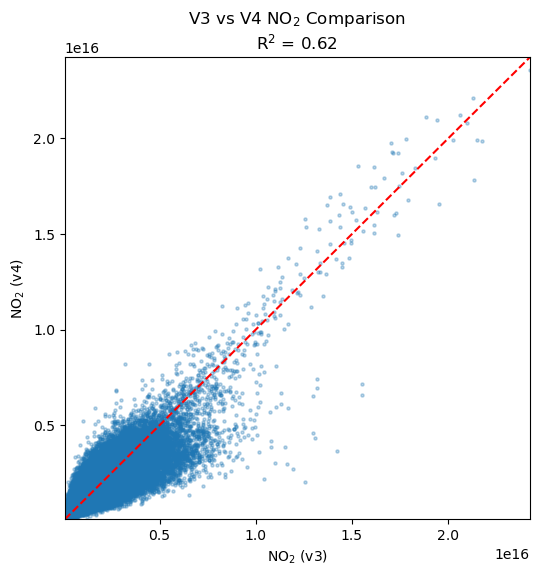

In [43]:
# drop NaNs just in case
df = merged.dropna(subset=['no2_scaled_by_hour', 'no2_mean_v4'])

# compute R and R²
r = np.corrcoef(df['no2_scaled_by_hour'], df['no2_mean_v4'])[0, 1]
r2 = r**2

plt.figure(figsize=(6,6))

plt.scatter(
    df['no2_scaled_by_hour'],
    df['no2_mean_v4'],
    alpha=0.3,
    s=5
)

# 1:1 line
lims = [
    min(df['no2_scaled_by_hour'].min(), df['no2_mean_v4'].min()),
    max(df['no2_scaled_by_hour'].max(), df['no2_mean_v4'].max())
]
plt.plot(lims, lims, 'r--')

plt.xlabel('NO$_2$ (v3)')
plt.ylabel('NO$_2$ (v4)')
plt.title(f'V3 vs V4 NO$_2$ Comparison\nR$^2$ = {r2:.2f}')

plt.xlim(lims)
plt.ylim(lims)

plt.show()

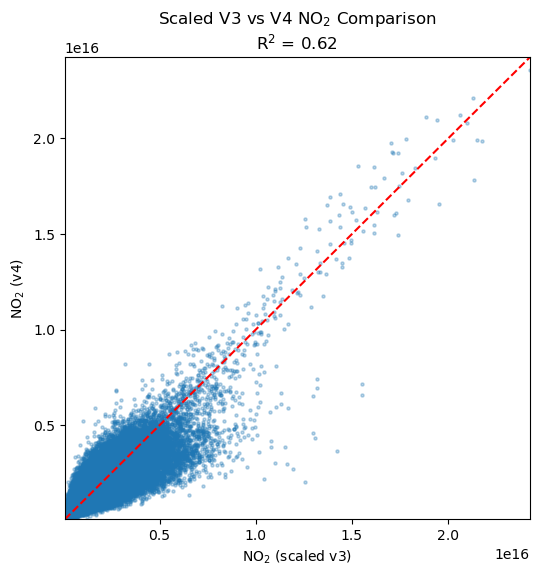

In [44]:
# drop NaNs just in case
df = merged.dropna(subset=['no2_scaled_by_hour', 'no2_mean_v4'])

# compute R and R²
r = np.corrcoef(df['no2_scaled_by_hour'], df['no2_mean_v4'])[0, 1]
r2 = r**2

plt.figure(figsize=(6,6))

plt.scatter(
    df['no2_scaled_by_hour'],
    df['no2_mean_v4'],
    alpha=0.3,
    s=5
)

# 1:1 line
lims = [
    min(df['no2_scaled_by_hour'].min(), df['no2_mean_v4'].min()),
    max(df['no2_scaled_by_hour'].max(), df['no2_mean_v4'].max())
]
plt.plot(lims, lims, 'r--')

plt.xlabel('NO$_2$ (scaled v3)')
plt.ylabel('NO$_2$ (v4)')
plt.title(f'Scaled V3 vs V4 NO$_2$ Comparison\nR$^2$ = {r2:.2f}')

plt.xlim(lims)
plt.ylim(lims)

plt.show()

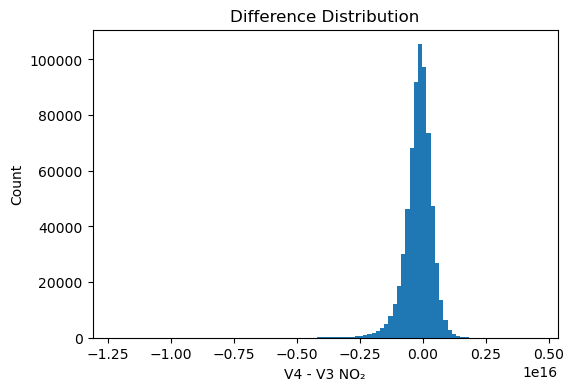

In [45]:
plt.figure(figsize=(6,4))
plt.hist(merged['diff'], bins=100)
plt.xlabel('V4 - V3 NO₂')
plt.ylabel('Count')
plt.title('Difference Distribution')
plt.show()

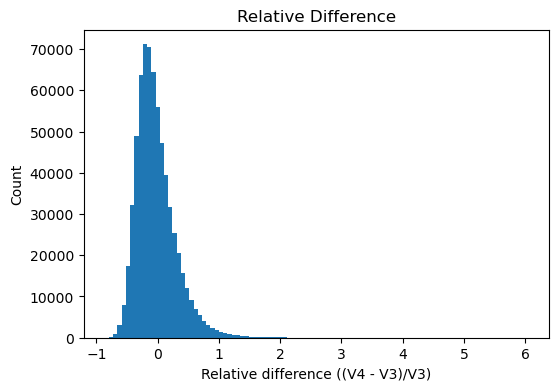

In [46]:
plt.figure(figsize=(6,4))
plt.hist(merged['rel_diff'], bins=100)
plt.xlabel('Relative difference ((V4 - V3)/V3)')
plt.ylabel('Count')
plt.title('Relative Difference')
plt.show()

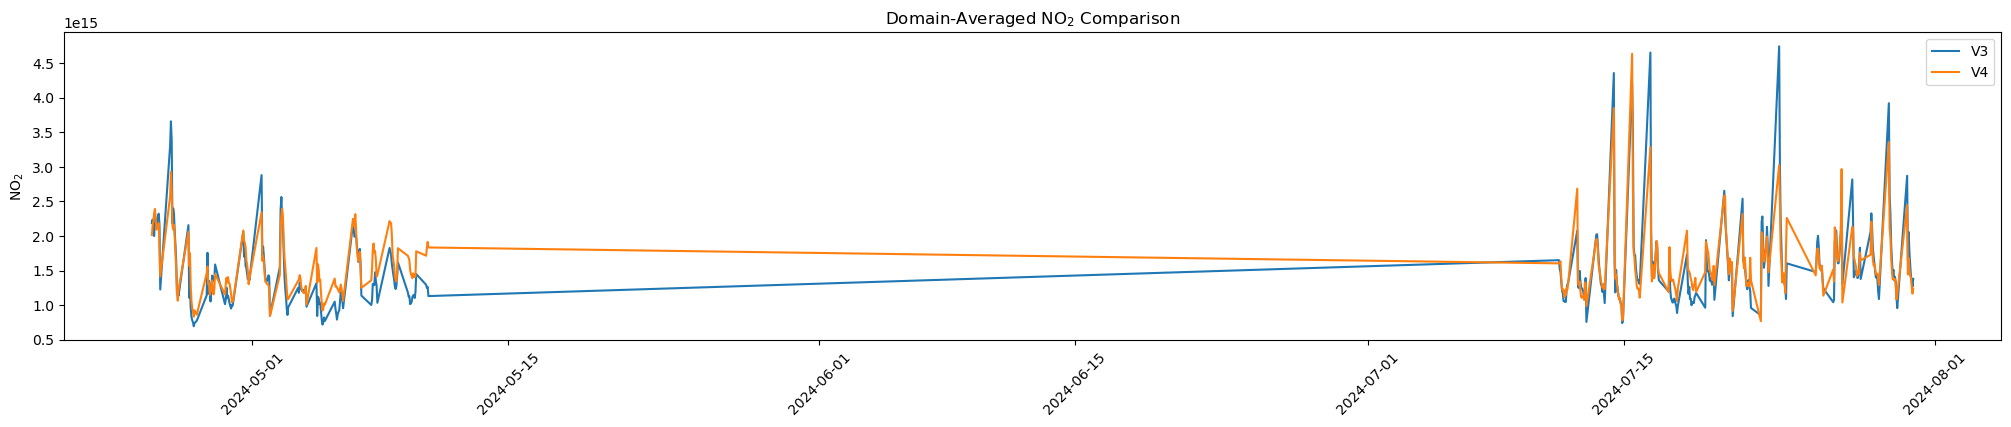

In [47]:
agg = (
    merged.groupby('datetime')
    .agg(
        v3_mean=('no2_scaled_by_hour', 'mean'),
        v4_mean=('no2_mean_v4', 'mean')
    )
)

plt.figure(figsize=(25,4))
plt.plot(agg.index, agg['v3_mean'], label='V3')
plt.plot(agg.index, agg['v4_mean'], label='V4')

plt.legend()
plt.xticks(rotation=45)
plt.title('Domain-Averaged NO$_2$ Comparison')
plt.ylabel('NO$_2$')
plt.show()

In [48]:
merged['is_pulse'] = merged['pulse_start'] == True

In [49]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'datetime_utc',
       'datetime_local', 'local_hour', 'state_name', 'no2_scaled_by_hour',
       'rolling_mean', 'rolling_std', 'pulse_threshold', 'above_3sd',
       'prev_above', 'run_id', 'run_len', 'pulse_start', 'hour_local',
       'no2_mean_v4', 'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4',
       'diff', 'rel_diff', 'is_pulse', 'hour', 'time_bin'],
      dtype='object')

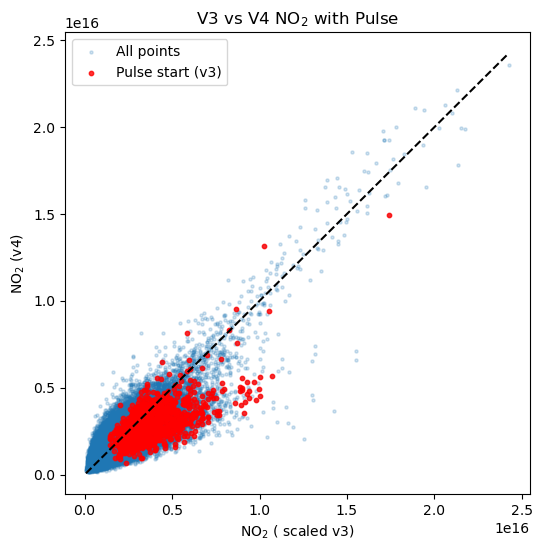

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

# background points
plt.scatter(
    merged['no2_scaled_by_hour'],
    merged['no2_mean_v4'],
    alpha=0.2,
    s=5,
    label='All points'
)

# pulse points (highlighted)
pulse_pts = merged[merged['is_pulse']]

plt.scatter(
    pulse_pts['no2_scaled_by_hour'],
    pulse_pts['no2_mean_v4'],
    color='red',
    s=10,
    label='Pulse start (v3)',
    alpha=0.8
)

# 1:1 line
lims = [
    min(merged['no2_scaled_by_hour'].min(), merged['no2_mean_v4'].min()),
    max(merged['no2_scaled_by_hour'].max(), merged['no2_mean_v4'].max())
]
plt.plot(lims, lims, 'k--')

plt.xlabel('NO$_2$ ( scaled v3)')
plt.ylabel('NO$_2$ (v4)')
plt.title('V3 vs V4 NO$_2$ with Pulse')
plt.legend()

plt.show()

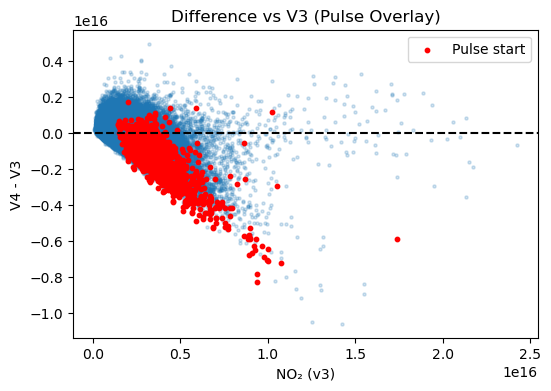

In [51]:
merged['diff'] = merged['no2_mean_v4'] - merged['no2_scaled_by_hour']

plt.figure(figsize=(6,4))

plt.scatter(
    merged['no2_scaled_by_hour'],
    merged['diff'],
    alpha=0.2,
    s=5
)

plt.scatter(
    pulse_pts['no2_scaled_by_hour'],
    pulse_pts['diff'],
    color='red',
    s=10,
    label='Pulse start'
)

plt.axhline(0, linestyle='--', color='k')

plt.xlabel('NO₂ (v3)')
plt.ylabel('V4 - V3')
plt.title('Difference vs V3 (Pulse Overlay)')
plt.legend()

plt.show()

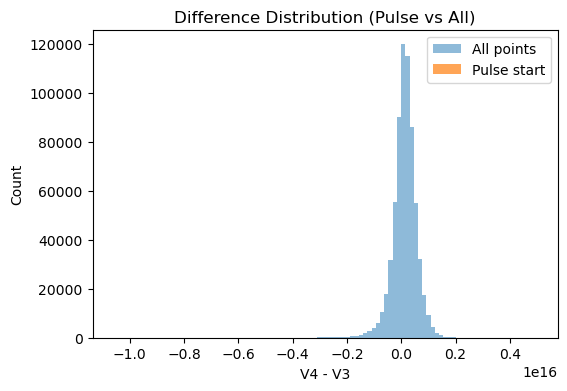

In [52]:
plt.figure(figsize=(6,4))

plt.hist(
    merged['diff'],
    bins=100,
    alpha=0.5,
    label='All points'
)

plt.hist(
    pulse_pts['diff'],
    bins=100,
    alpha=0.7,
    label='Pulse start'
)

plt.xlabel('V4 - V3')
plt.ylabel('Count')
plt.title('Difference Distribution (Pulse vs All)')
plt.legend()

plt.show()

In [53]:
pulse_pts['rel_diff'] = (pulse_pts['no2_mean_v4'] - pulse_pts['no2_scaled_by_hour']) / pulse_pts['no2_scaled_by_hour']

pulse_pts['rel_diff'].describe()

/tmp/ipykernel_116567/1446942939.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pulse_pts['rel_diff'] = (pulse_pts['no2_mean_v4'] - pulse_pts['no2_scaled_by_hour']) / pulse_pts['no2_scaled_by_hour']


count    1233.000000
mean       -0.176630
std         0.241890
min        -0.710796
25%        -0.366337
50%        -0.186910
75%        -0.012137
max         0.977535
Name: rel_diff, dtype: float64

In [54]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'datetime_utc',
       'datetime_local', 'local_hour', 'state_name', 'no2_scaled_by_hour',
       'rolling_mean', 'rolling_std', 'pulse_threshold', 'above_3sd',
       'prev_above', 'run_id', 'run_len', 'pulse_start', 'hour_local',
       'no2_mean_v4', 'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4',
       'diff', 'rel_diff', 'is_pulse', 'hour', 'time_bin'],
      dtype='object')

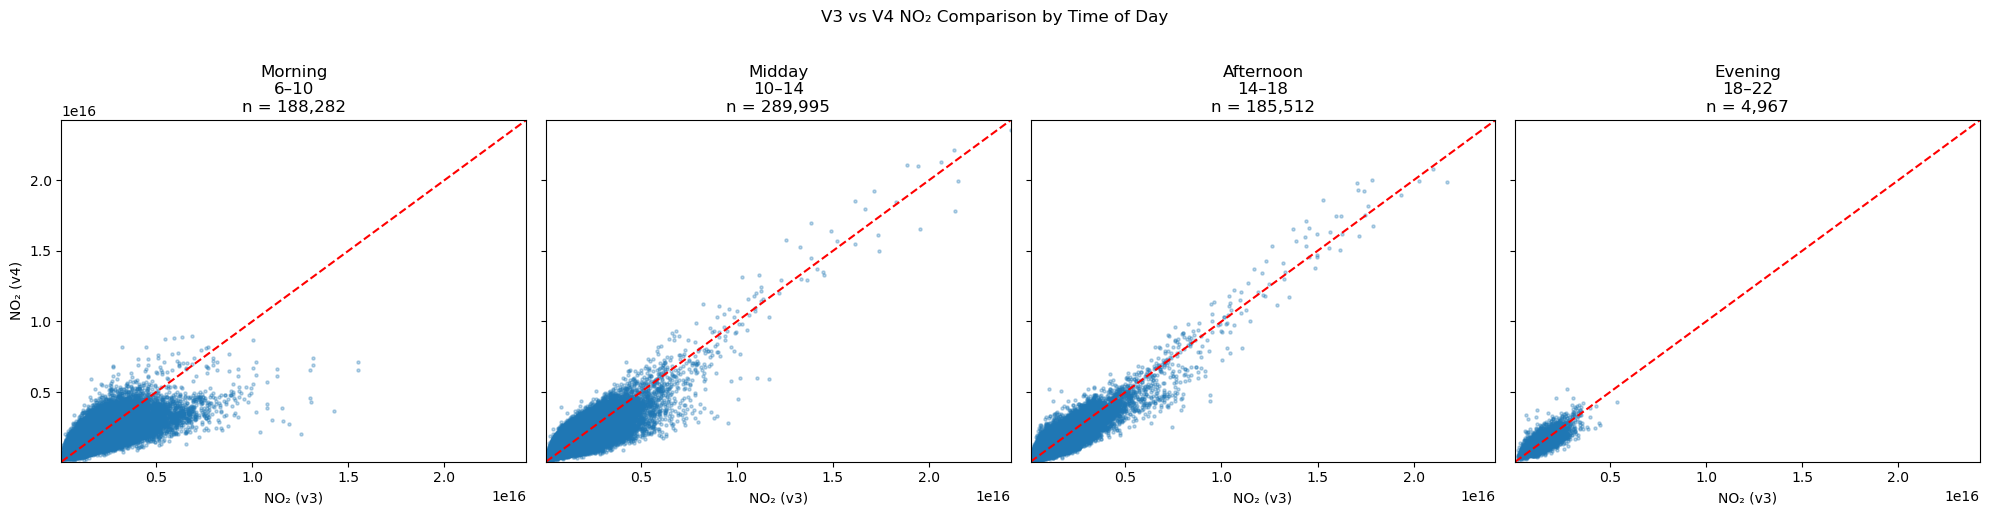

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# preserve timezone-aware datetime
merged['datetime_local'] = merged['datetime_local'].apply(pd.Timestamp)

# extract local hour correctly
merged['hour'] = merged['datetime_local'].apply(lambda x: x.hour)

# define time-of-day bins
def get_time_bin(hour):
    if 6 <= hour < 10:
        return 'Morning\n6–10'
    elif 10 <= hour < 14:
        return 'Midday\n10–14'
    elif 14 <= hour < 18:
        return 'Afternoon\n14–18'
    elif 18 <= hour < 22:
        return 'Evening\n18–22'
    else:
        return 'Night\n22–6'

merged['time_bin'] = merged['hour'].apply(get_time_bin)
time_bins = ['Morning\n6–10', 'Midday\n10–14', 'Afternoon\n14–18', 'Evening\n18–22']

# compute shared axis limits with some padding
all_vals = pd.concat([merged['no2_scaled_by_hour'], merged['no2_mean_v4']]).dropna()
lims = [all_vals.min(), all_vals.max()]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, tb in zip(axes, time_bins):
    subset = merged[merged['time_bin'] == tb].dropna(subset=['no2_scaled_by_hour', 'no2_mean_v4'])
    
    ax.scatter(
        subset['no2_scaled_by_hour'],
        subset['no2_mean_v4'],
        alpha=0.3,
        s=5
    )
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='1:1 line')
    ax.set_title(f'{tb}\nn = {len(subset):,}')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes:
    ax.set_xlabel('NO₂ (v3)')

axes[0].set_ylabel('NO₂ (v4)')
fig.suptitle('V3 vs V4 NO₂ Comparison by Time of Day', y=1.02)
plt.tight_layout()
plt.show()

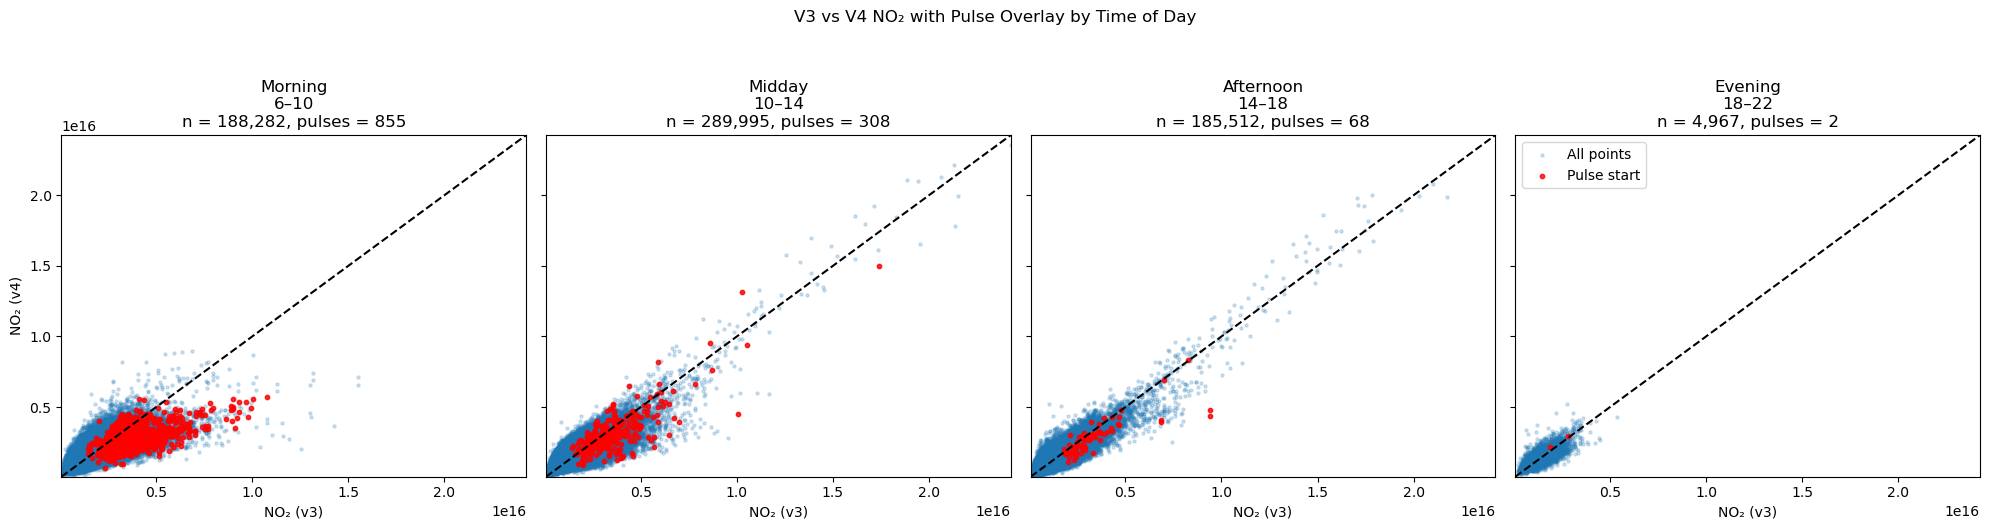

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, tb in zip(axes, time_bins):
    subset = merged[merged['time_bin'] == tb]
    pulses = subset[subset['pulse_start'] == True]

    ax.scatter(
        subset['no2_scaled_by_hour'],
        subset['no2_mean_v4'],
        alpha=0.2,
        s=5,
        label='All points'
    )

    ax.scatter(
        pulses['no2_scaled_by_hour'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=10,
        label='Pulse start'
    )

    ax.plot(lims, lims, 'k--')
    ax.set_title(f'{tb}\nn = {len(subset):,}, pulses = {len(pulses):,}')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes:
    ax.set_xlabel('NO₂ (v3)')

axes[0].set_ylabel('NO₂ (v4)')
axes[-1].legend()

fig.suptitle('V3 vs V4 NO₂ with Pulse Overlay by Time of Day', y=1.05)
plt.tight_layout()
plt.show()

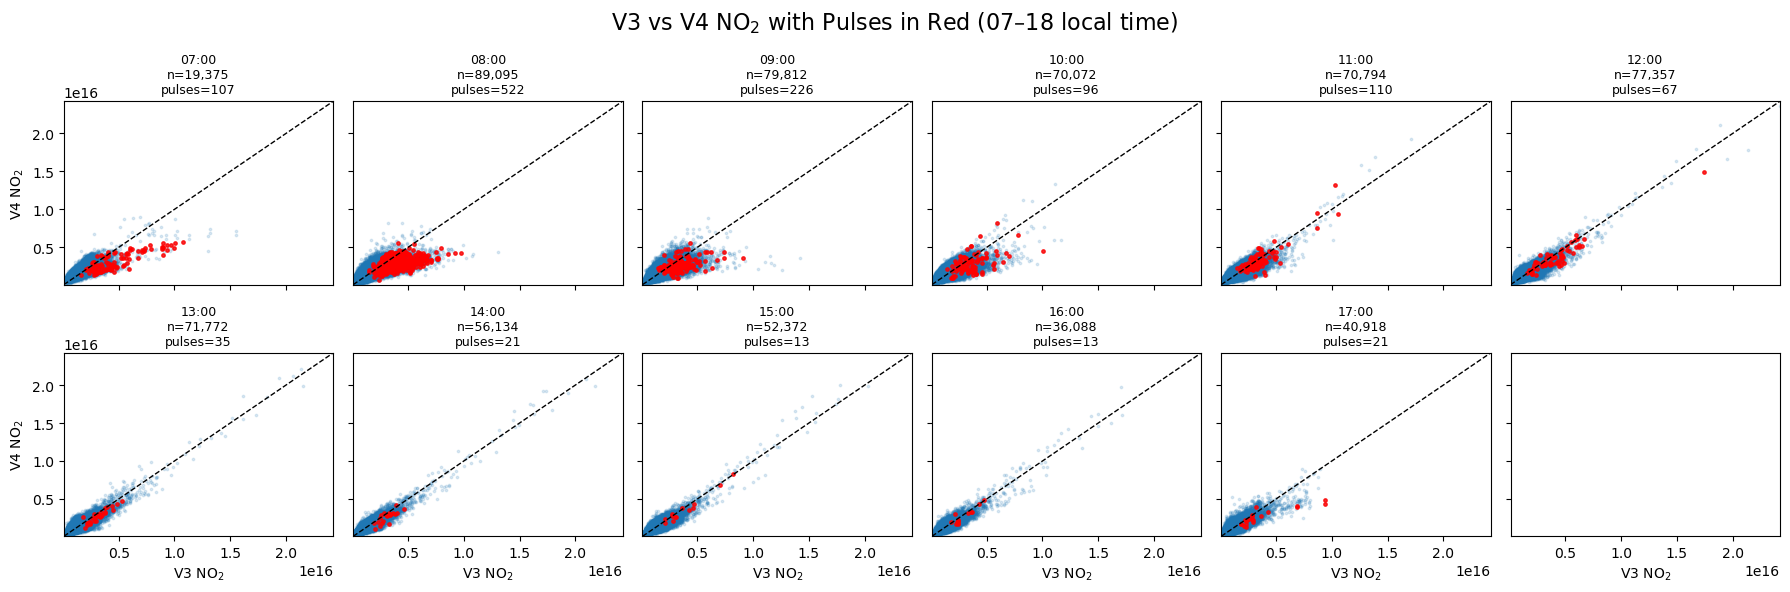

In [58]:
hours = list(range(7, 18))  # 7–18 inclusive

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged['hour'] == h]
    pulses = subset[subset['pulse_start'] == True]

    # background
    ax.scatter(
        subset['no2_scaled_by_hour'],
        subset['no2_mean_v4'],
        alpha=0.15,
        s=3
    )

    # pulses
    ax.scatter(
        pulses['no2_scaled_by_hour'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=6
    )

    # 1:1 line
    ax.plot(lims, lims, 'k--', linewidth=1)

    ax.set_title(f'{h:02d}:00\nn={len(subset):,}\npulses={len(pulses):,}', fontsize=9)
    ax.set_xlim(lims)
    ax.set_ylim(lims)

# label only outer axes (cleaner)
for ax in axes[6:]:
    ax.set_xlabel('V3 NO$_2$')

for ax in axes[::6]:
    ax.set_ylabel('V4 NO$_2$')

fig.suptitle('V3 vs V4 NO$_2$ with Pulses in Red (07–18 local time)', fontsize=16)
plt.tight_layout()
plt.show()

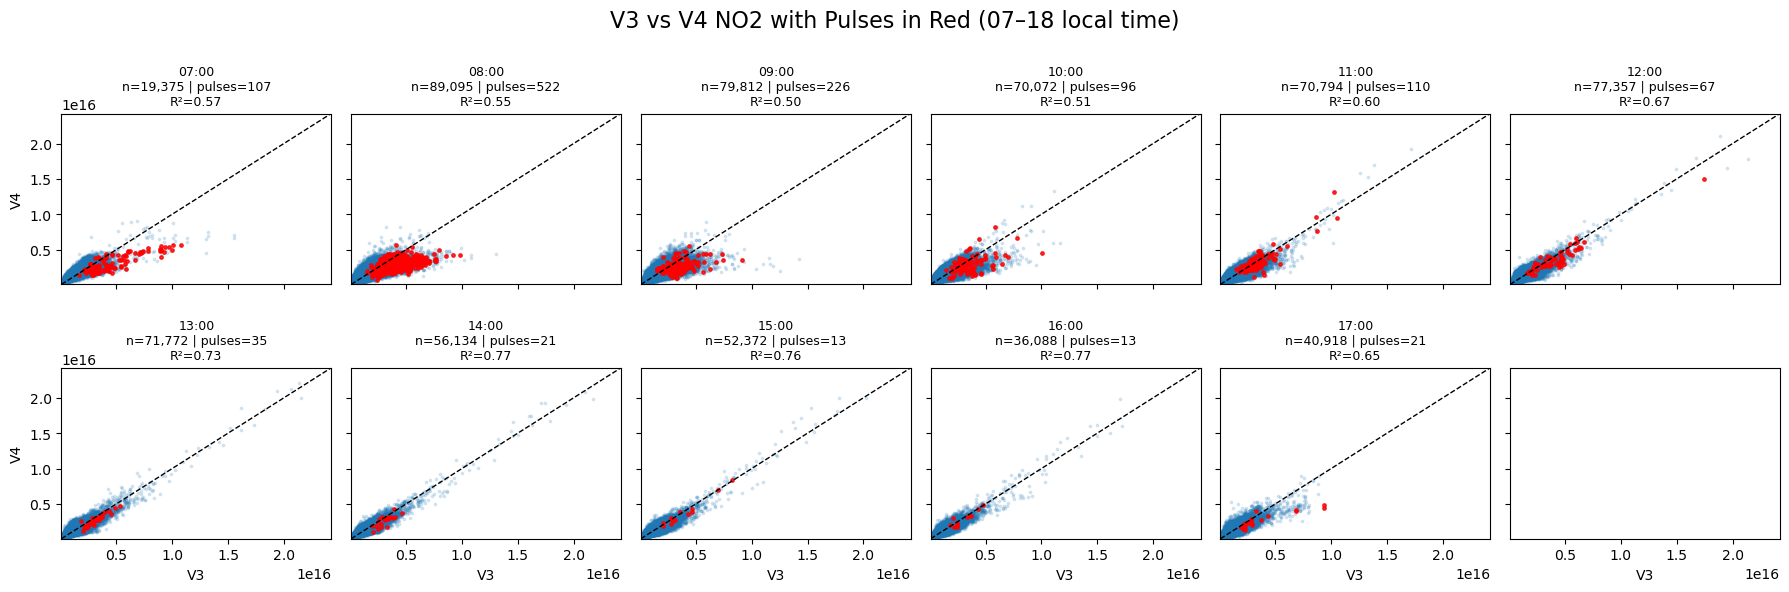

In [59]:
import numpy as np
import matplotlib.pyplot as plt

hours = list(range(7, 18))  # 7–18 inclusive

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

r2_dict = {}  # store values if you want later

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged['hour'] == h]

    # drop NaNs just in case
    subset = subset.dropna(subset=['no2_scaled_by_hour', 'no2_mean_v4'])

    pulses = subset[subset['pulse_start'] == True]

    #compute R2
    if len(subset) > 2:
        r = np.corrcoef(subset['no2_scaled_by_hour'], subset['no2_mean_v4'])[0, 1]
        r2 = r**2
    else:
        r2 = np.nan

    r2_dict[h] = r2

    # background
    ax.scatter(
        subset['no2_scaled_by_hour'],
        subset['no2_mean_v4'],
        alpha=0.15,
        s=3
    )

    # pulses
    ax.scatter(
        pulses['no2_scaled_by_hour'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=6
    )

    # 1:1 line
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_title(
        f'{h:02d}:00\nn={len(subset):,} | pulses={len(pulses):,}\nR²={r2:.2f}',
        fontsize=9
    )

    ax.set_xlim(lims)
    ax.set_ylim(lims)

# axis labels
for ax in axes[6:]:
    ax.set_xlabel('V3')

for ax in axes[::6]:
    ax.set_ylabel('V4')

fig.suptitle('V3 vs V4 NO2 with Pulses in Red (07–18 local time)', fontsize=16)
plt.tight_layout()
plt.show()

# creating scaling factors for each hour

In [41]:
from scipy import stats

# ── Per-hour scaling factors ──────────────────────────────────────────────────
# For each hour we fit three estimators:
#   1. Median ratio  : robust, no intercept — good when outliers are present
#   2. OLS + intercept: standard linear regression
#   3. OLS through origin: least-squares slope forced through (0,0)
#
# To bring V4 onto the 1:1 line with V3, divide V4 by the slope (or ratio).
hours = list(range(7, 19))

records = []
for h in hours:
    sub = merged[merged["hour"] == h].dropna(subset=["no2_mean_v3", "no2_mean_v4"])
    x = sub["no2_mean_v3"].values
    y = sub["no2_mean_v4"].values

    if len(sub) < 5:
        continue

    # 1. Median ratio (robust to outliers)
    ratio_mask = x > 0
    median_ratio = np.median(y[ratio_mask] / x[ratio_mask])

    # 2. OLS with intercept
    slope_ols, intercept_ols, r, p, se = stats.linregress(x, y)
    r2_ols = r**2

    # 3. Least-squares through origin: slope = Σ(x·y) / Σ(x²)
    slope_origin = np.dot(x, y) / np.dot(x, x)

    records.append(dict(
        hour=h,
        n=len(sub),
        median_ratio=median_ratio,
        slope_ols=slope_ols,
        intercept_ols=intercept_ols,
        r2_ols=r2_ols,
        slope_origin=slope_origin,
    ))

scaling_df = pd.DataFrame(records)
print(scaling_df.to_string(index=False, float_format="{:.4f}".format))

 hour     n  median_ratio  slope_ols        intercept_ols  r2_ols  slope_origin
    7 19375        1.0562     0.4820 844673178318585.8750  0.5661        0.8319
    8 89095        1.0777     0.5267 765690078615746.5000  0.5524        0.8754
    9 79812        1.0426     0.5269 808517341887562.3750  0.4966        0.8941
   10 70072        1.0074     0.5198 721274273680601.0000  0.5121        0.8668
   11 70794        0.9537     0.5821 543720152662936.7500  0.5974        0.8551
   12 77357        0.9001     0.6214 423185898571035.8750  0.6730        0.8345
   13 71772        0.8652     0.6486 330527398389732.6250  0.7348        0.8131
   14 56134        0.8182     0.6371 278345544250004.0000  0.7743        0.7703
   15 52372        0.7936     0.6008 295150745564498.1250  0.7568        0.7393
   16 36088        0.7804     0.5985 285741381817881.2500  0.7704        0.7285
   17 40918        0.8318     0.5321 435230887883374.3750  0.6513        0.7418
   18  4967        0.7833     0.5338 418

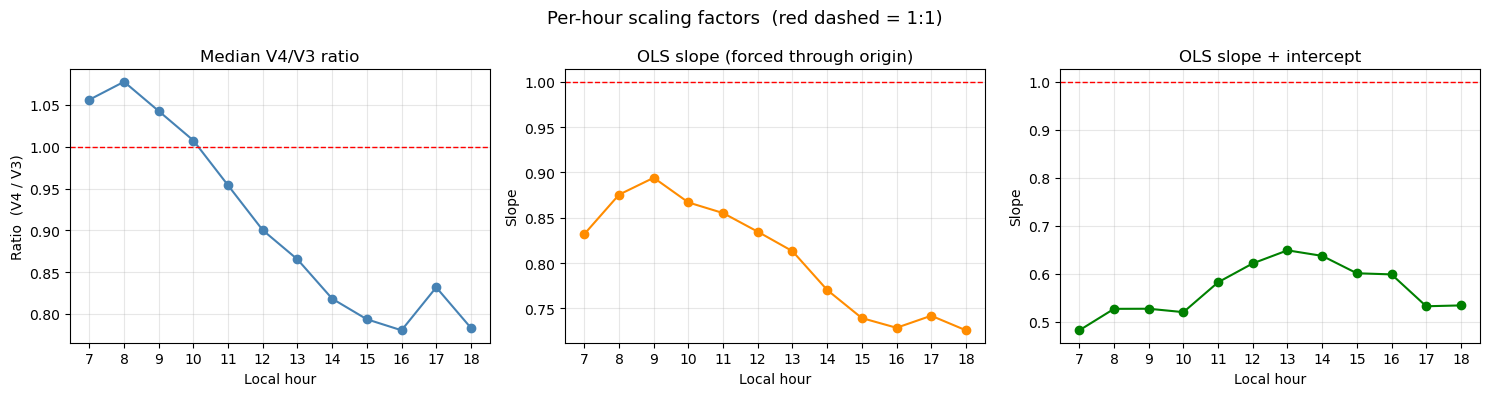

In [42]:
# ── Visualise per-hour scaling factors ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

axes[0].plot(scaling_df["hour"], scaling_df["median_ratio"], "o-", color="steelblue")
axes[0].axhline(1, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Median V4/V3 ratio")
axes[0].set_ylabel("Ratio  (V4 / V3)")

axes[1].plot(scaling_df["hour"], scaling_df["slope_origin"], "o-", color="darkorange")
axes[1].axhline(1, color="red", linestyle="--", linewidth=1)
axes[1].set_title("OLS slope (forced through origin)")
axes[1].set_ylabel("Slope")

axes[2].plot(scaling_df["hour"], scaling_df["slope_ols"], "o-", color="green")
axes[2].axhline(1, color="red", linestyle="--", linewidth=1)
axes[2].set_title("OLS slope + intercept")
axes[2].set_ylabel("Slope")

for ax in axes:
    ax.set_xlabel("Local hour")
    ax.set_xticks(scaling_df["hour"])
    ax.grid(True, alpha=0.3)

fig.suptitle("Per-hour scaling factors  (red dashed = 1:1)", fontsize=13)
plt.tight_layout()
plt.show()

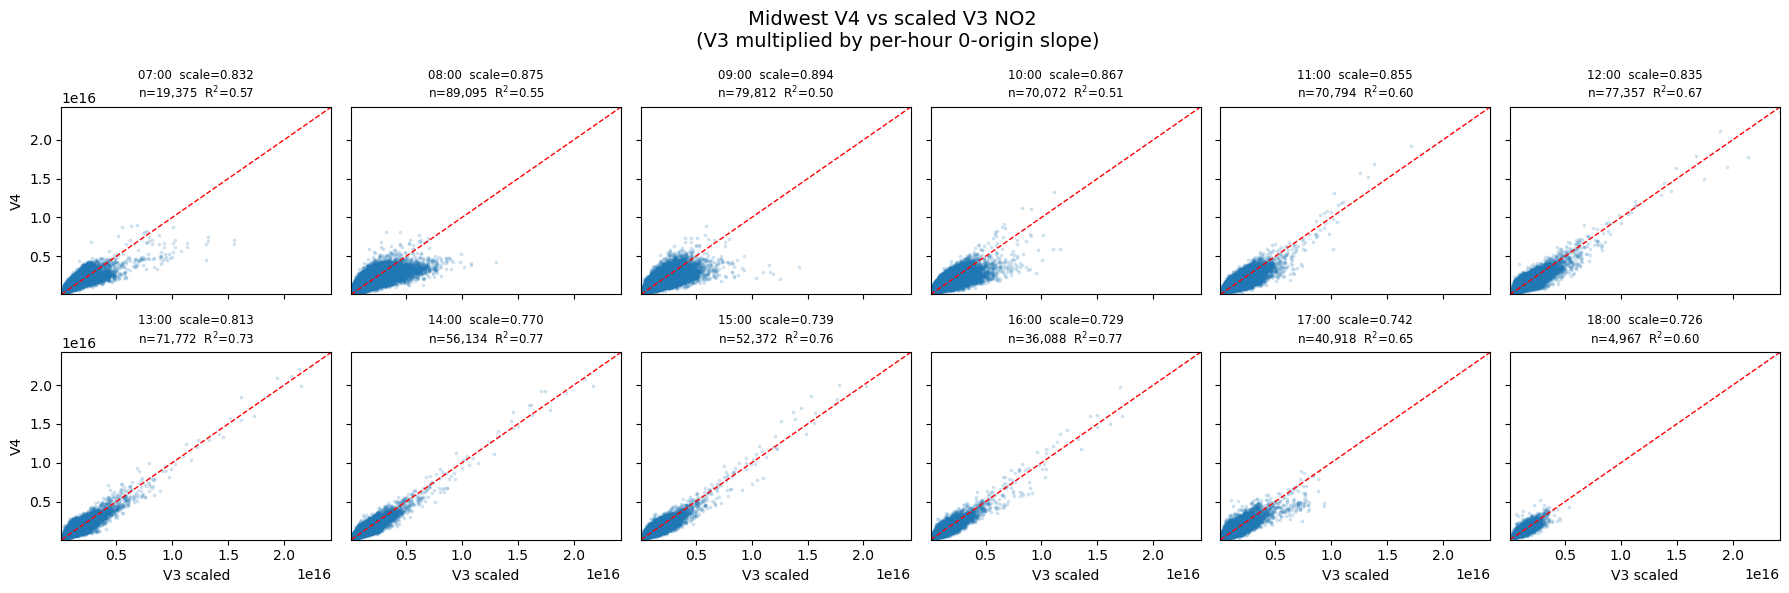

In [43]:
# ── Apply per-hour scaling to V3 and re-plot ──────────────────────────────────
# V4 is left untouched. V3 is scaled down by the per-hour OLS-origin slope,
# so that scaled V3 ≈ V4 on the 1:1 line.
# Swap "slope_origin" → "median_ratio" in scaling_df if preferred.
scale_map = dict(zip(scaling_df["hour"], scaling_df["slope_origin"]))

merged["no2_v3_scaled"] = merged.apply(
    lambda row: row["no2_mean_v3"] * scale_map[row["hour"]]
    if row["hour"] in scale_map else np.nan,
    axis=1
)

lims_scaled = [
    min(merged["no2_v3_scaled"].min(), merged["no2_mean_v4"].min()),
    max(merged["no2_v3_scaled"].max(), merged["no2_mean_v4"].max())
]

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged["hour"] == h].dropna(subset=["no2_v3_scaled", "no2_mean_v4"])
    sf = scale_map.get(h, float("nan"))

    ax.scatter(subset["no2_v3_scaled"], subset["no2_mean_v4"], alpha=0.15, s=3)
    ax.plot(lims_scaled, lims_scaled, "r--", linewidth=1)

    r = np.corrcoef(subset["no2_v3_scaled"], subset["no2_mean_v4"])[0, 1]
    r2 = r**2

    ax.set_title(
        f"{h:02d}:00  scale={sf:.3f}\nn={len(subset):,}  R$^2$={r2:.2f}",
        fontsize=8.5
    )
    ax.set_xlim(lims_scaled)
    ax.set_ylim(lims_scaled)

for ax in axes[6:]:
    ax.set_xlabel("V3 scaled")
for ax in axes[::6]:
    ax.set_ylabel("V4")

fig.suptitle(" Midwest V4 vs scaled V3 NO2  \n (V3 multiplied by per-hour 0-origin slope)", fontsize=14)
plt.tight_layout()
plt.show()

In [44]:
scaling_df

,hour,n,median_ratio,slope_ols,intercept_ols,r2_ols,slope_origin
0,7,19375,1.056197,0.481975,8.446732e+14,0.566050,0.831940
1,8,89095,1.077682,0.526694,7.656901e+14,0.552367,0.875446
2,9,79812,1.042624,0.526900,8.085173e+14,0.496593,0.894077
3,10,70072,1.007424,0.519804,7.212743e+14,0.512117,0.866824
4,11,70794,0.953716,0.582076,5.437202e+14,0.597423,0.855114
5,12,77357,0.900121,0.621433,4.231859e+14,0.673033,0.834543
6,13,71772,0.865226,0.648644,3.305274e+14,0.734756,0.813060
7,14,56134,0.818199,0.637103,2.783455e+14,0.774251,0.770254
8,15,52372,0.793600,0.600836,2.951507e+14,0.756838,0.739253
9,16,36088,0.780423,0.598495,2.857414e+14,0.770366,0.728544


In [45]:
scaling_df_filtered = scaling_df.drop(columns={'median_ratio','slope_ols','intercept_ols','r2_ols'})

In [46]:
scaling_df_filtered

,hour,n,slope_origin
0,7,19375,0.831940
1,8,89095,0.875446
2,9,79812,0.894077
3,10,70072,0.866824
4,11,70794,0.855114
5,12,77357,0.834543
6,13,71772,0.813060
7,14,56134,0.770254
8,15,52372,0.739253
9,16,36088,0.728544


In [47]:
#saving 
scaling_df_filtered.to_parquet("/global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet", engine='pyarrow')
print("Saved: /global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet")


Saved: /global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet


# by state

In [50]:
import numpy as np
import matplotlib.pyplot as plt

hours = list(range(11, 23))

states = sorted(merged['state_name'].dropna().unique())

for state in states:
    state_df = merged[merged['state_name'] == state].copy()

    # skip states with very little data
    if len(state_df) < 10:
        continue

    # state-specific plot limits
    lims = [
        min(state_df['no2_mean_v3'].min(), state_df['no2_mean_v4'].min()),
        max(state_df['no2_mean_v3'].max(), state_df['no2_mean_v4'].max())
    ]

    fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
    axes = axes.flatten()

    r2_dict = {}

    for i, h in enumerate(hours):
        ax = axes[i]

        subset = state_df[state_df['hour'] == h]
        subset = subset.dropna(subset=['no2_mean_v3', 'no2_mean_v4'])

        pulses = subset[subset['pulse_start'] == True]

        # compute R²
        if len(subset) > 2:
            r = np.corrcoef(subset['no2_mean_v3'], subset['no2_mean_v4'])[0, 1]
            r2 = r**2
        else:
            r2 = np.nan

        r2_dict[h] = r2

        ax.scatter(
            subset['no2_mean_v3'],
            subset['no2_mean_v4'],
            alpha=0.15,
            s=3
        )

        ax.scatter(
            pulses['no2_mean_v3'],
            pulses['no2_mean_v4'],
            color='red',
            alpha=0.8,
            s=6
        )

        ax.plot(lims, lims, 'k--', linewidth=1)

        ax.set_title(
            f'{h:02d}:00\nn={len(subset):,} | pulses={len(pulses):,}\nR²={r2:.2f}',
            fontsize=9
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    for ax in axes[6:]:
        ax.set_xlabel('V3')

    for ax in axes[::6]:
        ax.set_ylabel('V4')

    fig.suptitle(f'{state}: V3 vs V4 NO₂ with Pulses in Red (07–18 local time)', fontsize=16)
    plt.tight_layout()
    plt.show()

KeyError: 'state_name'

State×hour cells: 216
  Using state-specific factor : 213
  Using domain fallback       : 3

       state  hour     n  used_fallback  median_ratio  slope_origin  slope_ols         intercept_ols  r2_ols
    Arkansas     7   346          False        0.7366        0.6841     0.4234  739188052993508.2500  0.4130
    Arkansas     8   671          False        0.8816        0.8818     0.6755  500750431057000.7500  0.5184
    Arkansas     9   483          False        0.9804        0.9265     0.5466  766126008305485.1250  0.4633
    Arkansas    10   410          False        0.9863        0.9604     0.6080  613426954046841.6250  0.4620
    Arkansas    11   365          False        0.9650        0.9484     0.5777  604659517876218.2500  0.4599
    Arkansas    12   441          False        0.8913        0.8899     0.6026  480915555689345.8750  0.5987
    Arkansas    13   429          False        0.8808        0.8648     0.7057  266177218803140.3750  0.7350
    Arkansas    14   390          F

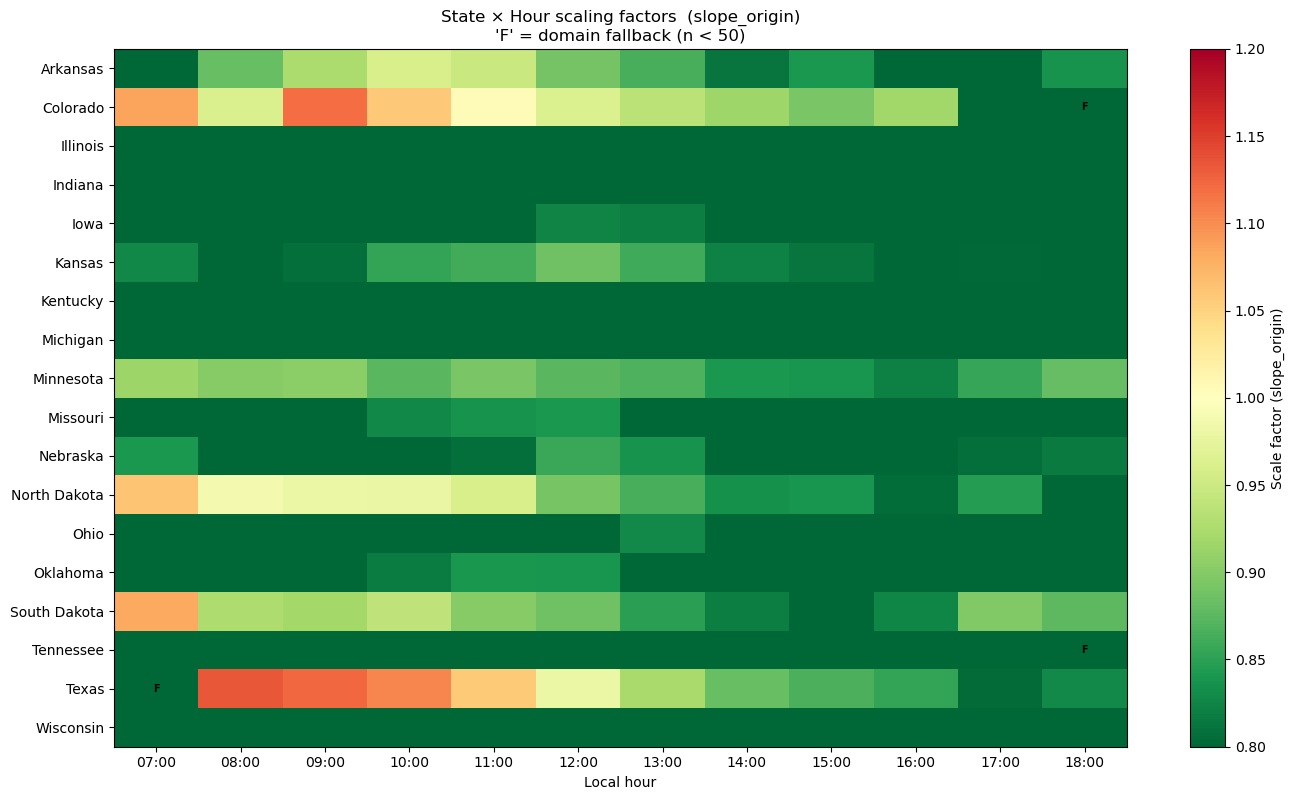

In [46]:
from scipy import stats

# ── Parameters ────────────────────────────────────────────────────────────────
MIN_N = 50          # minimum observations to trust a state×hour factor
ESTIMATOR = "slope_origin"   # "slope_origin" | "median_ratio" | "slope_ols"
HOURS = list(range(7, 19))

# ── Step 1: Domain-wide per-hour factors (fallback) ───────────────────────────
domain_records = []
for h in HOURS:
    sub = merged[merged["hour"] == h].dropna(subset=["no2_mean_v3", "no2_mean_v4"])
    x, y = sub["no2_mean_v3"].values, sub["no2_mean_v4"].values
    if len(sub) < 5:
        continue
    valid = x > 0
    domain_records.append(dict(
        hour=h,
        n=len(sub),
        median_ratio=np.median(y[valid] / x[valid]),
        slope_origin=np.dot(x, y) / np.dot(x, x),
        **dict(zip(
            ["slope_ols", "intercept_ols", "r2_ols"],
            [v for v in stats.linregress(x, y)[:3]]  # slope, intercept, r
        )),
    ))

domain_df = pd.DataFrame(domain_records)
domain_df["r2_ols"] = domain_df["r2_ols"] ** 2   # r → r²
domain_fallback = dict(zip(domain_df["hour"], domain_df[ESTIMATOR]))

# ── Step 2: State×hour factors ────────────────────────────────────────────────
states = sorted(merged["state_name"].dropna().unique())
state_records = []

for state in states:
    state_df = merged[merged["state_name"] == state]
    for h in HOURS:
        sub = state_df[state_df["hour"] == h].dropna(
            subset=["no2_mean_v3", "no2_mean_v4"]
        )
        x, y = sub["no2_mean_v3"].values, sub["no2_mean_v4"].values
        n = len(sub)

        if n >= MIN_N:
            valid = x > 0
            median_ratio  = np.median(y[valid] / x[valid]) if valid.sum() > 0 else np.nan
            slope_origin  = np.dot(x, y) / np.dot(x, x)
            sl, ic, r, *_ = stats.linregress(x, y)
            r2_ols        = r ** 2
            slope_ols, intercept_ols = sl, ic
            used_fallback = False
        else:
            # Not enough data — use domain-wide hour factor
            median_ratio = slope_origin = domain_fallback.get(h, np.nan)
            slope_ols    = domain_fallback.get(h, np.nan)
            intercept_ols = 0.0
            r2_ols        = np.nan
            used_fallback = True

        state_records.append(dict(
            state=state,
            hour=h,
            n=n,
            used_fallback=used_fallback,
            median_ratio=median_ratio,
            slope_origin=slope_origin,
            slope_ols=slope_ols,
            intercept_ols=intercept_ols,
            r2_ols=r2_ols,
        ))

state_hour_df = pd.DataFrame(state_records)

print(f"State×hour cells: {len(state_hour_df)}")
print(f"  Using state-specific factor : {(~state_hour_df['used_fallback']).sum()}")
print(f"  Using domain fallback       : {state_hour_df['used_fallback'].sum()}")
print()
print(state_hour_df.to_string(index=False, float_format="{:.4f}".format))

# ── Step 3: Apply to merged ───────────────────────────────────────────────────
# Build a fast lookup dict:  (state, hour) → scale factor
scale_map = {
    (row["state"], int(row["hour"])): row[ESTIMATOR]
    for _, row in state_hour_df.iterrows()
}

merged["no2_v3_scaled"] = [
    row["no2_mean_v3"] * scale_map.get((row["state_name"], int(row["hour"])), np.nan)
    for _, row in merged.iterrows()
]

# ── Step 4: Quick QC plot — factor heatmap ────────────────────────────────────
pivot = state_hour_df.pivot(index="state", columns="hour", values=ESTIMATOR)
fallback_pivot = state_hour_df.pivot(index="state", columns="hour", values="used_fallback")

fig, ax = plt.subplots(figsize=(14, max(4, len(states) * 0.45)))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn_r", vmin=0.8, vmax=1.2)
plt.colorbar(im, ax=ax, label=f"Scale factor ({ESTIMATOR})")

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f"{h:02d}:00" for h in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

# Mark fallback cells with an 'F'
for i, state in enumerate(pivot.index):
    for j, h in enumerate(pivot.columns):
        if fallback_pivot.loc[state, h]:
            ax.text(j, i, "F", ha="center", va="center", fontsize=7,
                    color="black", fontweight="bold")

ax.set_title(
    f"State × Hour scaling factors  ({ESTIMATOR})\n"
    f"'F' = domain fallback (n < {MIN_N})",
    fontsize=12
)
ax.set_xlabel("Local hour")
plt.tight_layout()
plt.show()


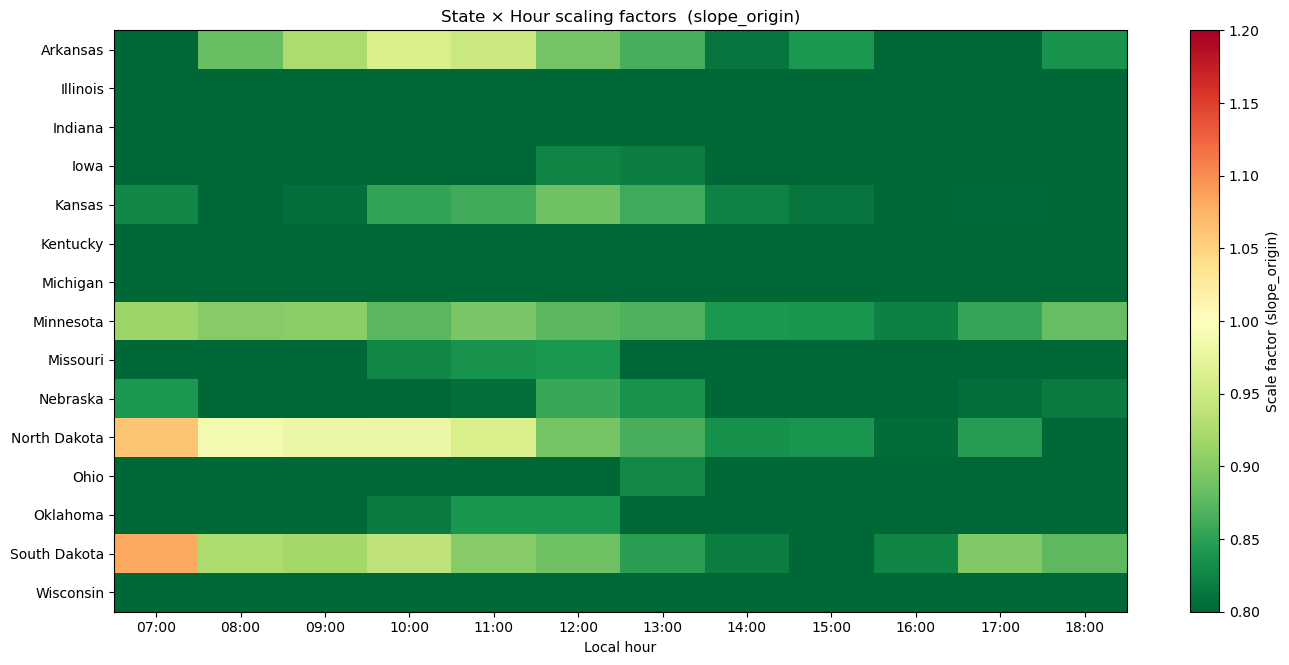

In [55]:
# Set to None to plot all states, or specify a list:
STATES_TO_PLOT = ['Arkansas','Illinois','Indiana','Iowa','Kansas','Kentucky','Michigan','Minnesota','Missouri','Nebraska','North Dakota','Ohio','Oklahoma',
                  'South Dakota','Wisconsin']
all_states = sorted(merged["state_name"].dropna().unique())
# ── Heatmap ───────────────────────────────────────────────────────────────────
plot_states = STATES_TO_PLOT if STATES_TO_PLOT is not None else all_states

invalid = [s for s in plot_states if s not in all_states]
if invalid:
    print(f"Warning: states not found and skipped: {invalid}")
    plot_states = [s for s in plot_states if s in all_states]

plot_df        = state_hour_df[state_hour_df["state"].isin(plot_states)]
pivot          = plot_df.pivot(index="state", columns="hour", values=ESTIMATOR)
fallback_pivot = plot_df.pivot(index="state", columns="hour", values="used_fallback")

fig, ax = plt.subplots(figsize=(14, max(4, len(plot_states) * 0.45)))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn_r", vmin=0.8, vmax=1.2)
plt.colorbar(im, ax=ax, label=f"Scale factor ({ESTIMATOR})")

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f"{h:02d}:00" for h in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

for i, state in enumerate(pivot.index):
    for j, h in enumerate(pivot.columns):
        if fallback_pivot.loc[state, h]:
            ax.text(j, i, "F", ha="center", va="center", fontsize=7,
                    color="black", fontweight="bold")

ax.set_title(
    f"State × Hour scaling factors  ({ESTIMATOR})",
    fontsize=12
)
ax.set_xlabel("Local hour")
plt.tight_layout()
plt.show()

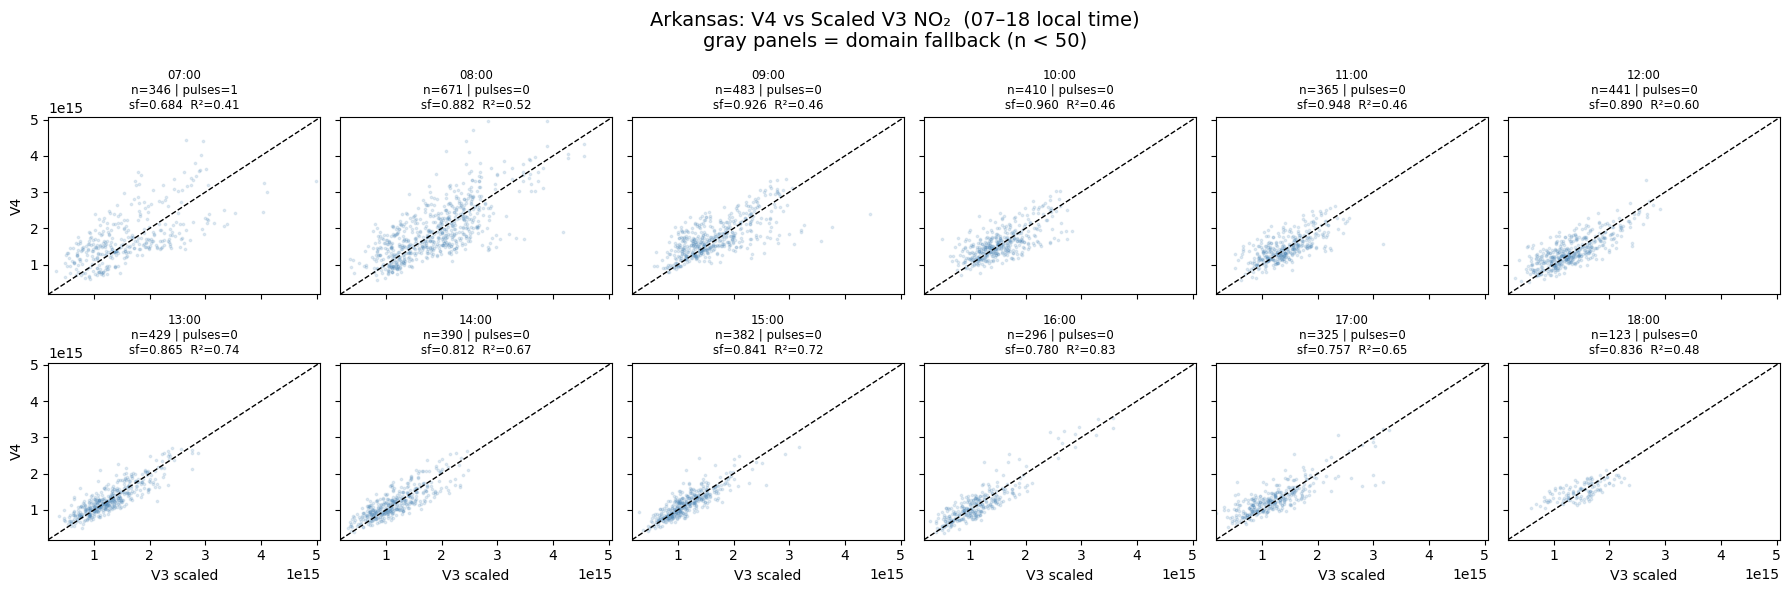

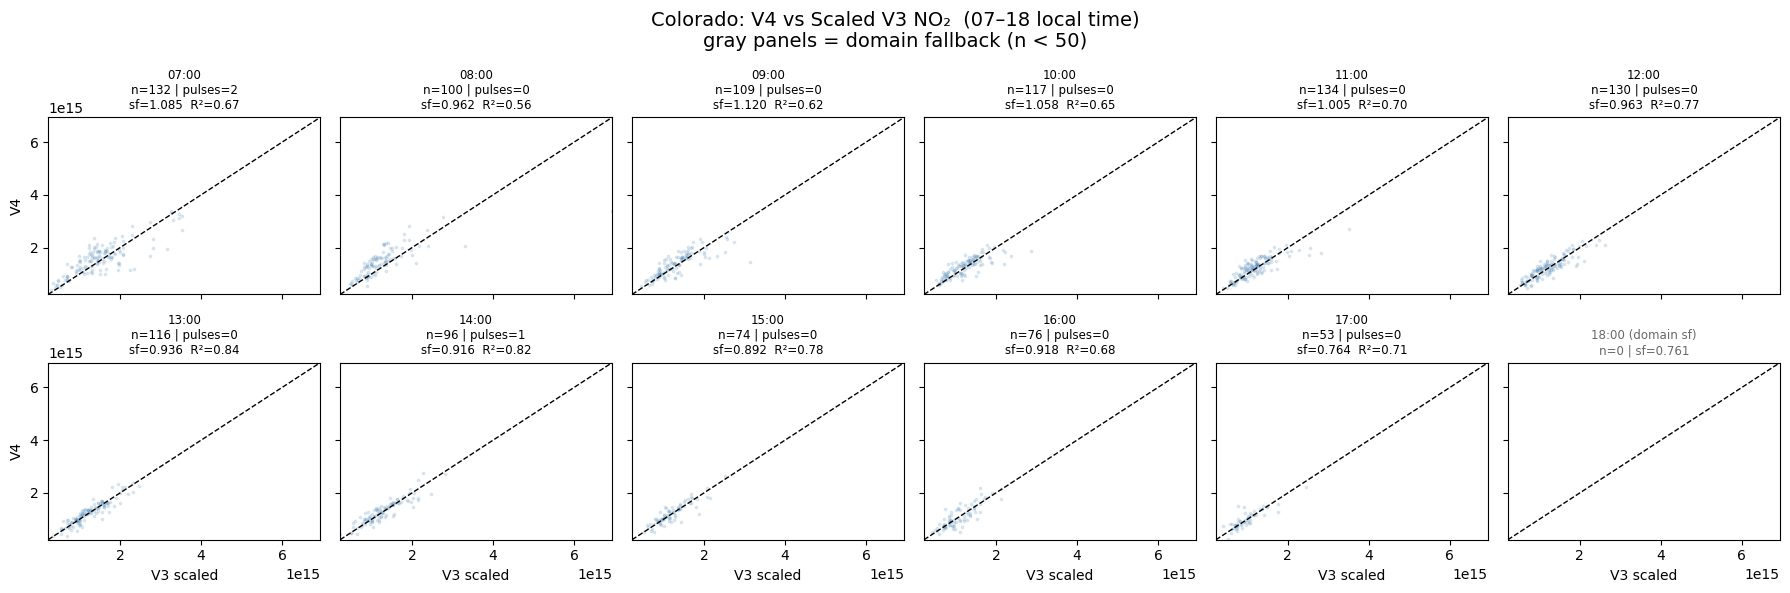

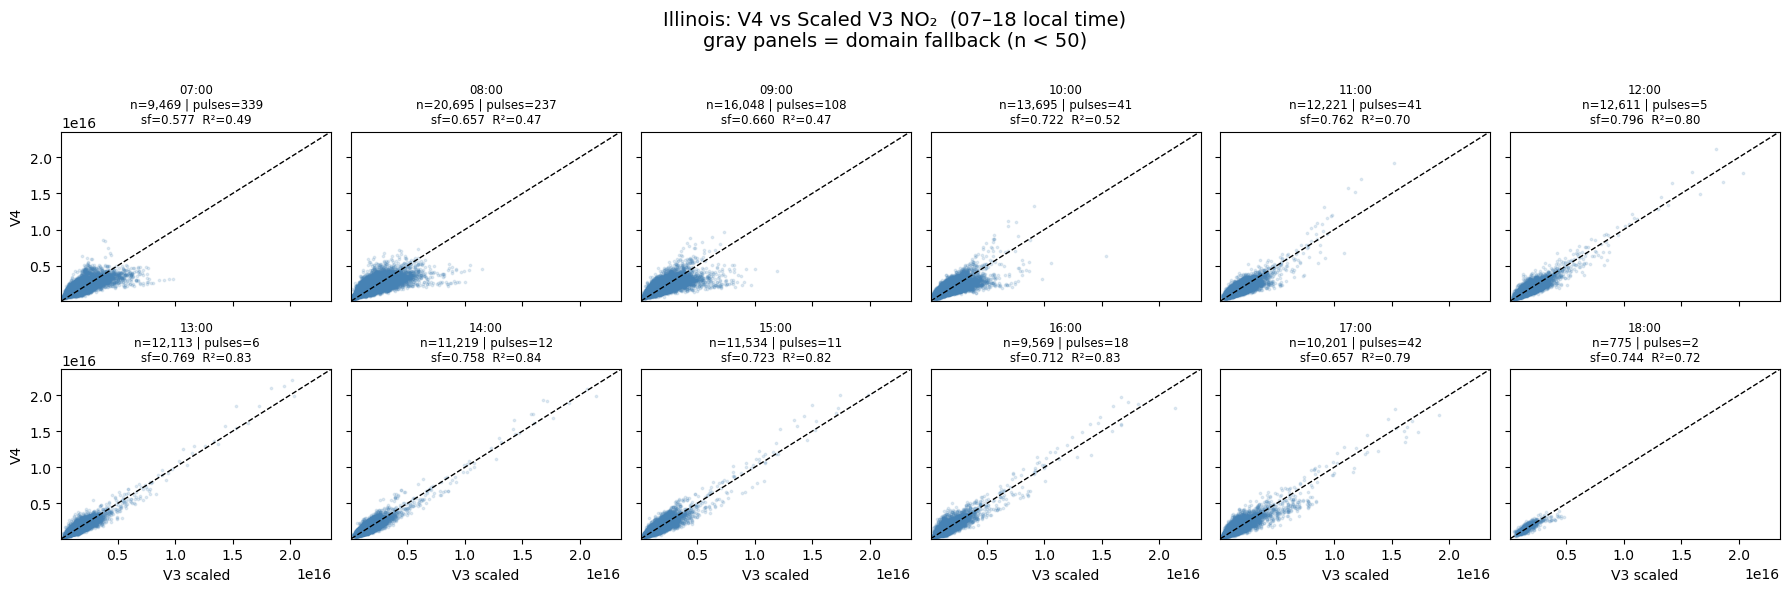

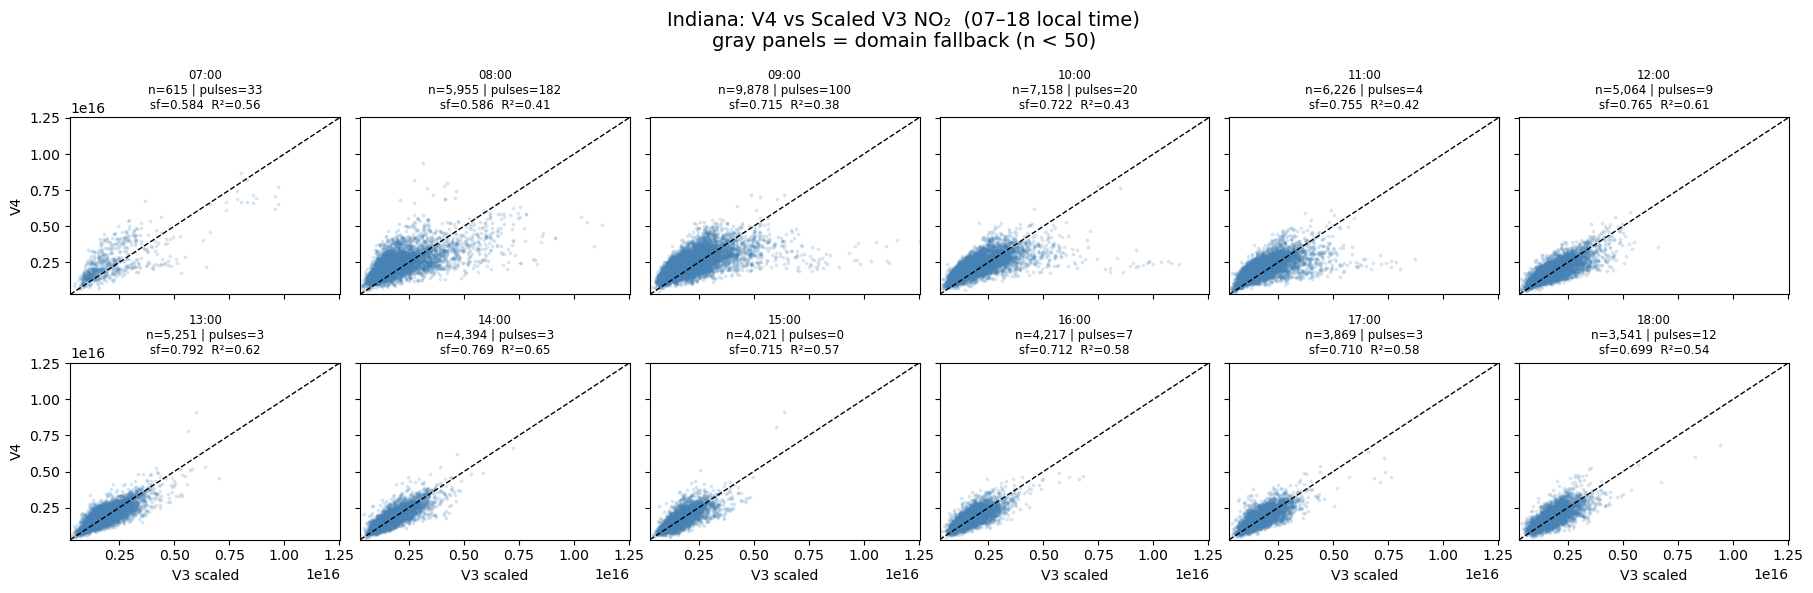

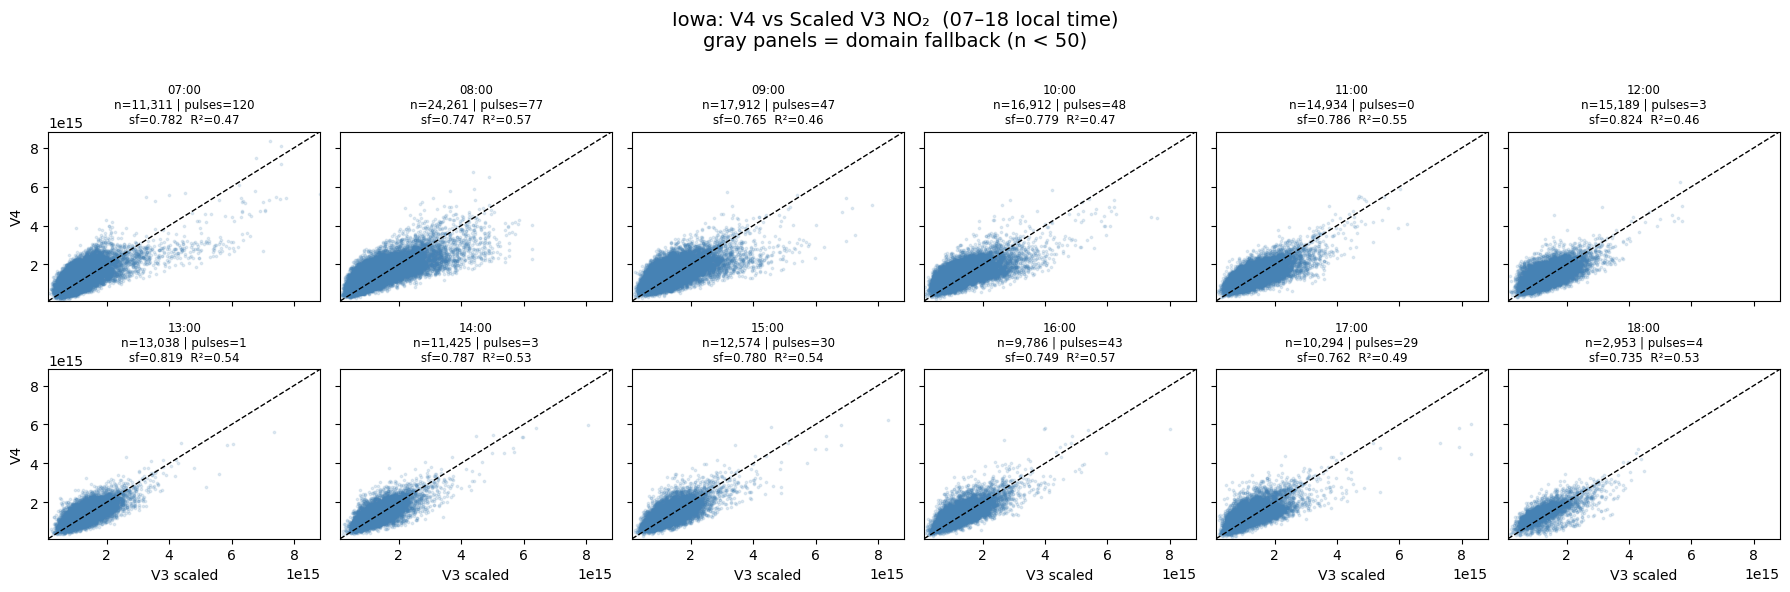

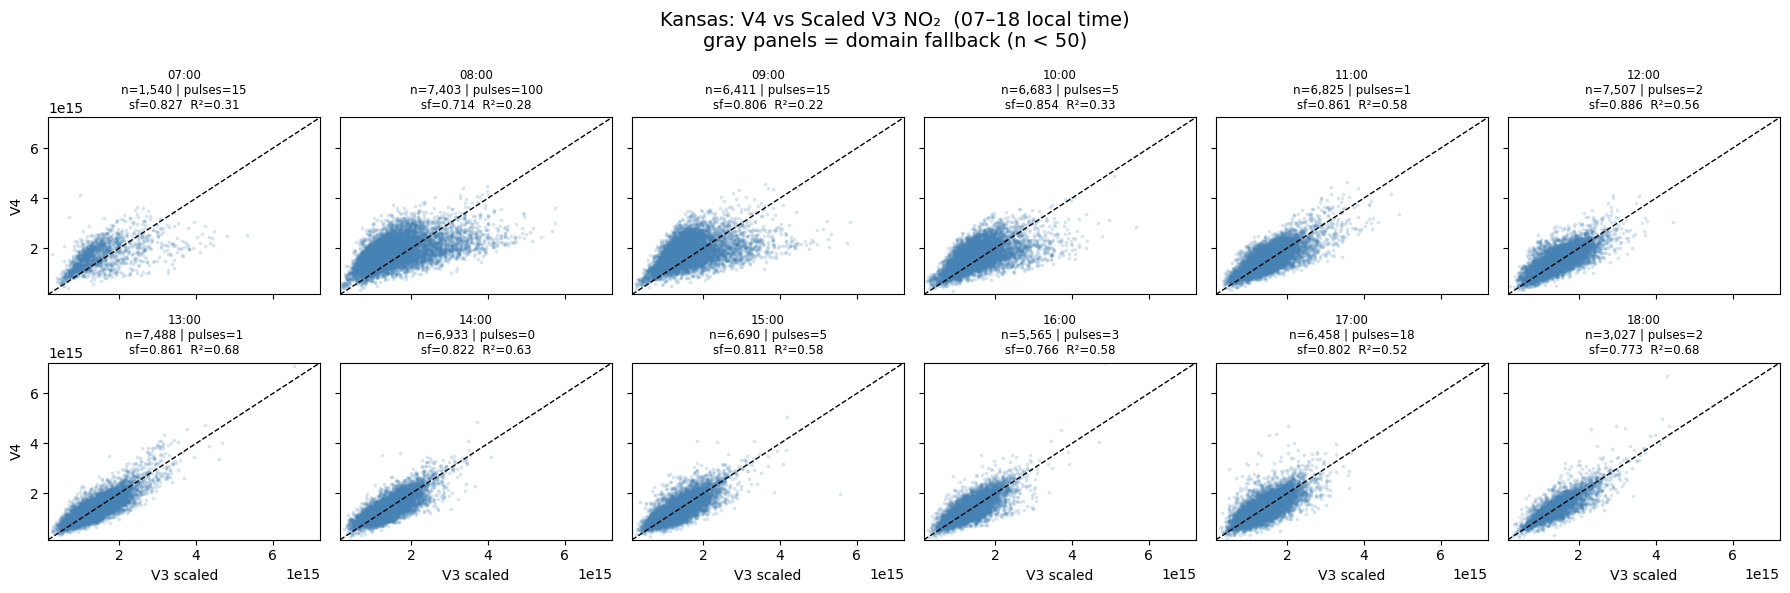

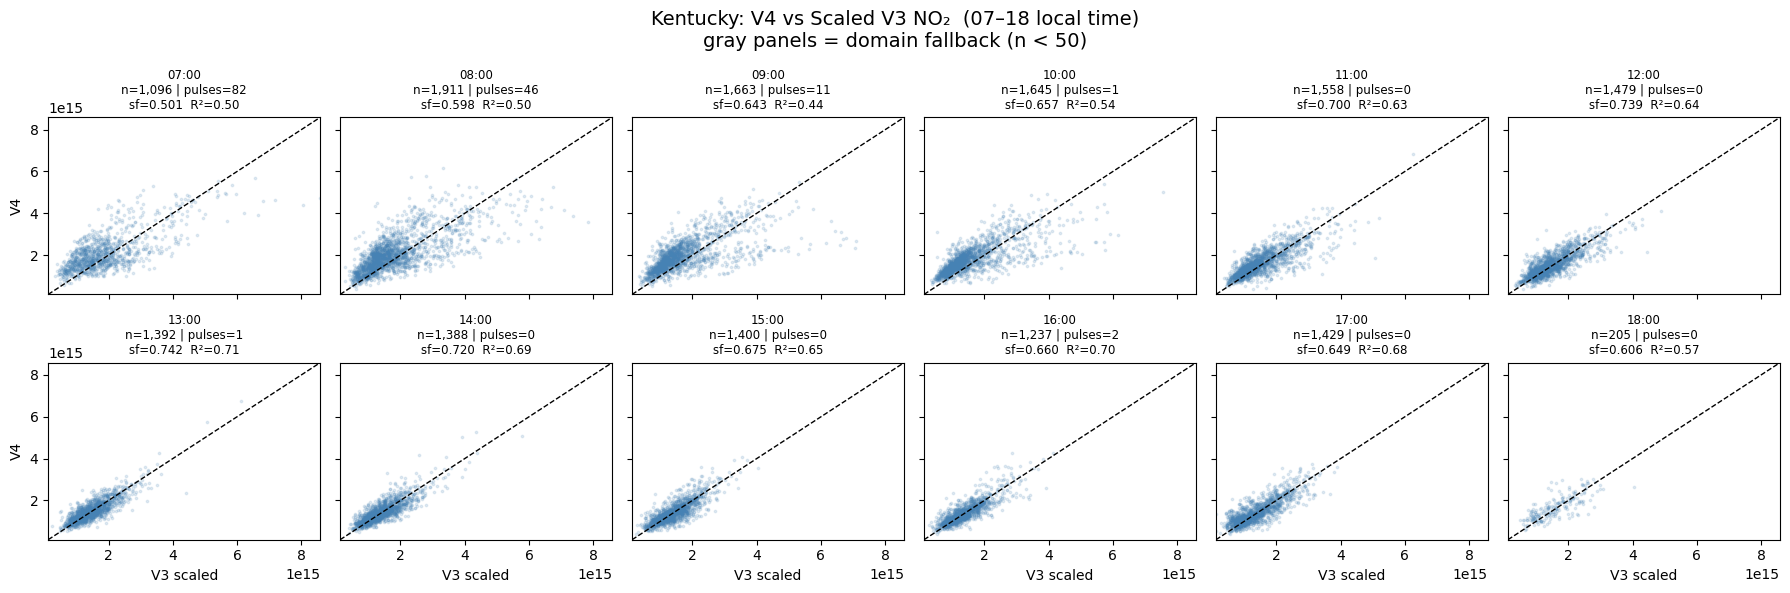

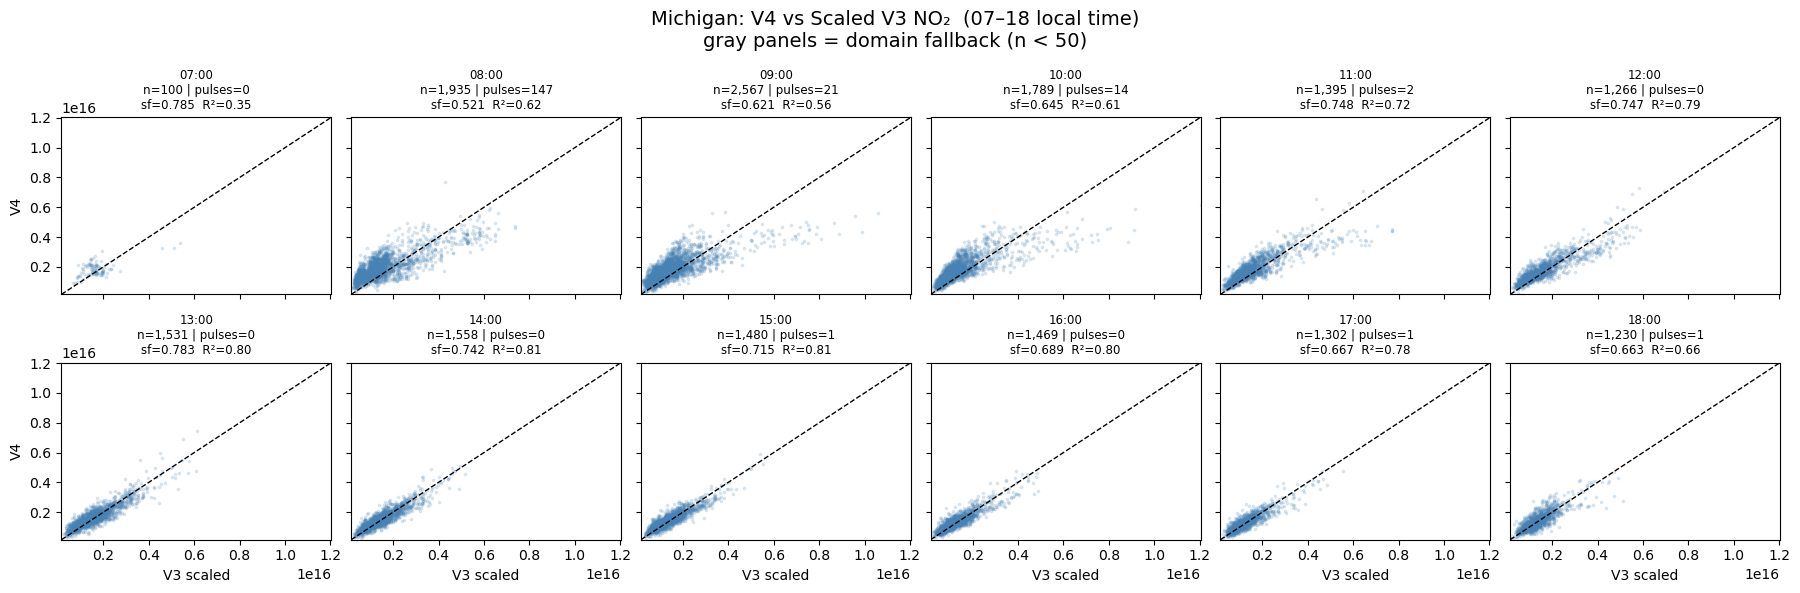

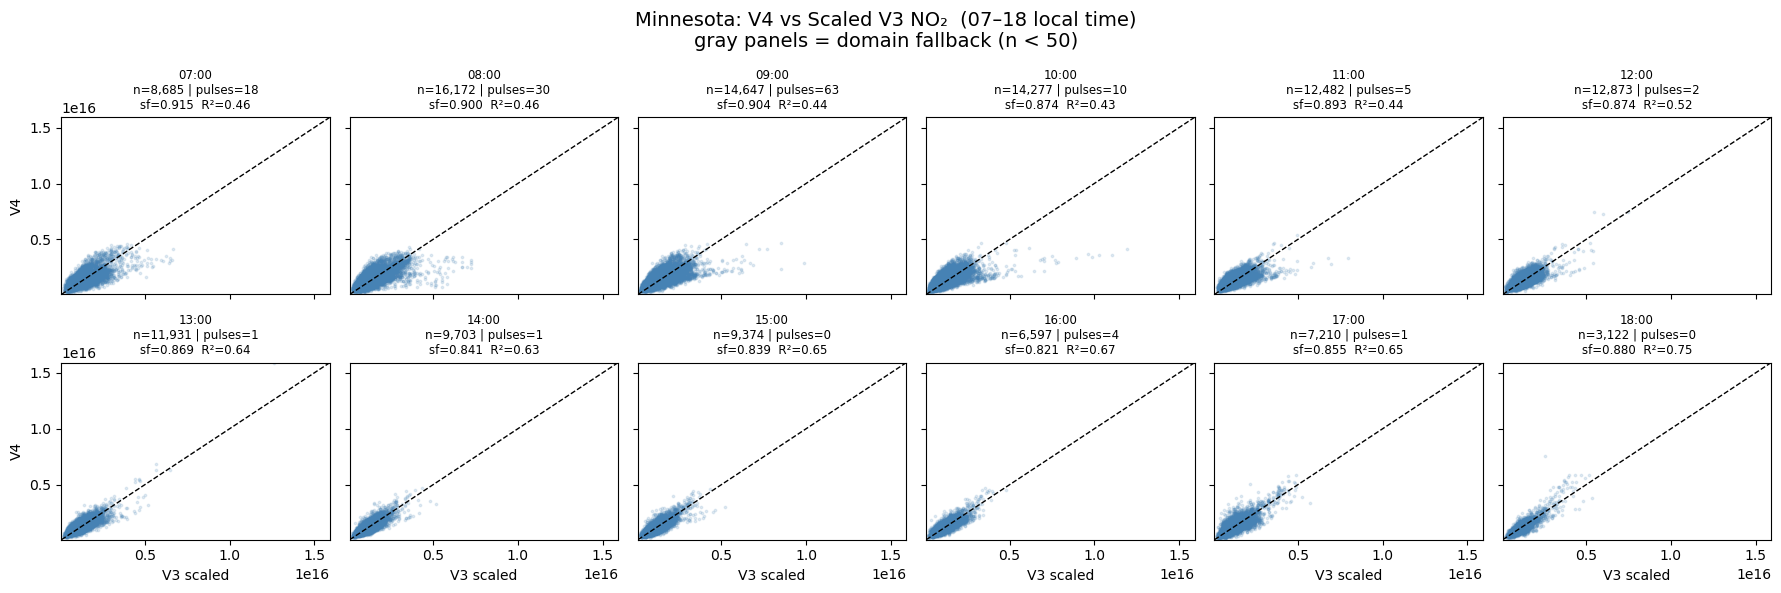

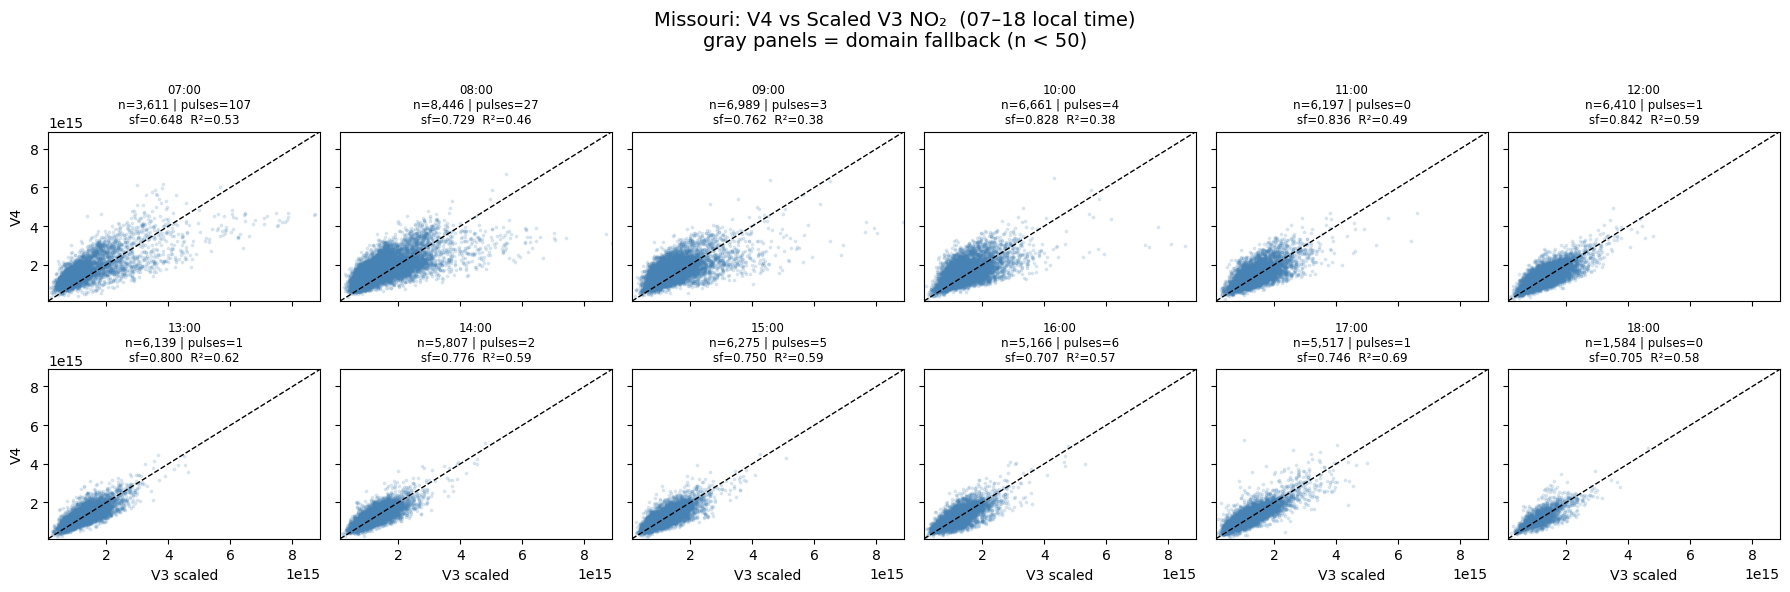

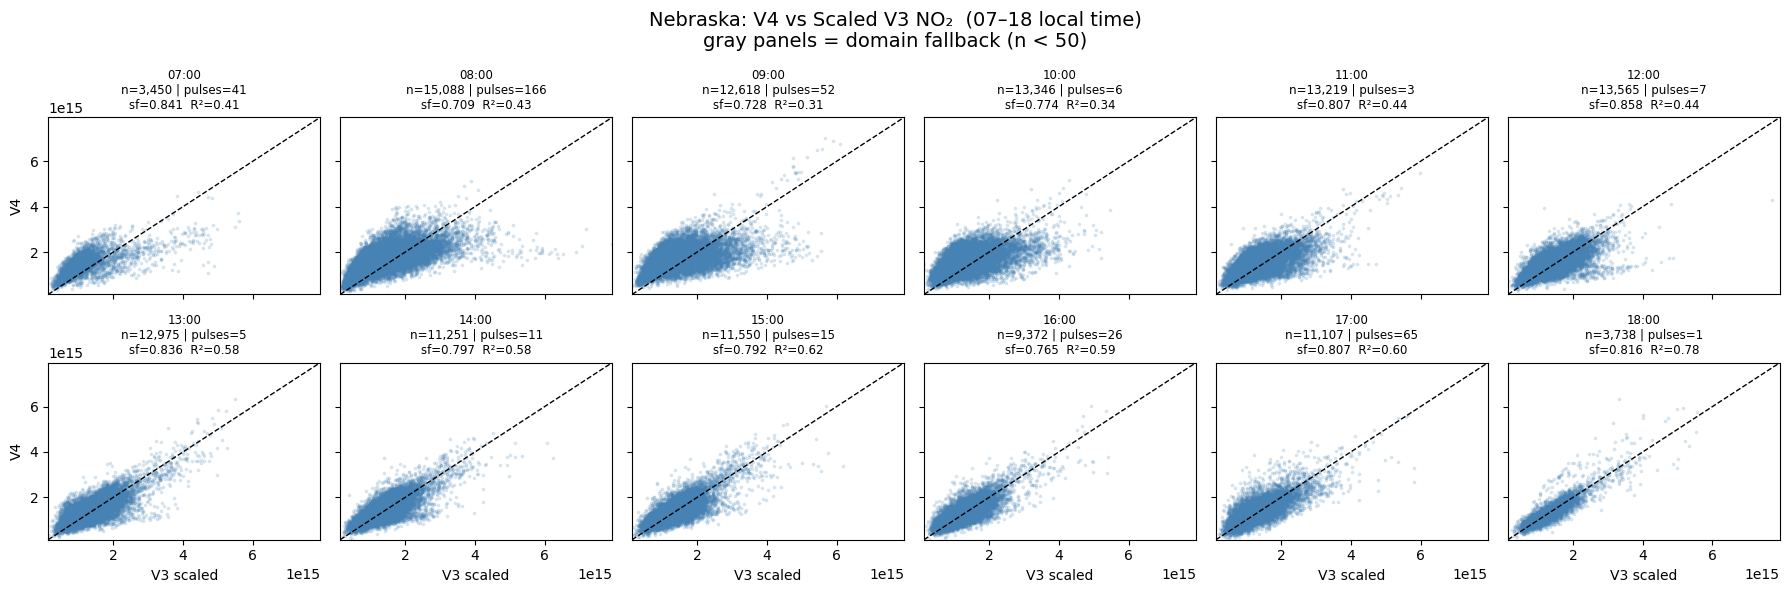

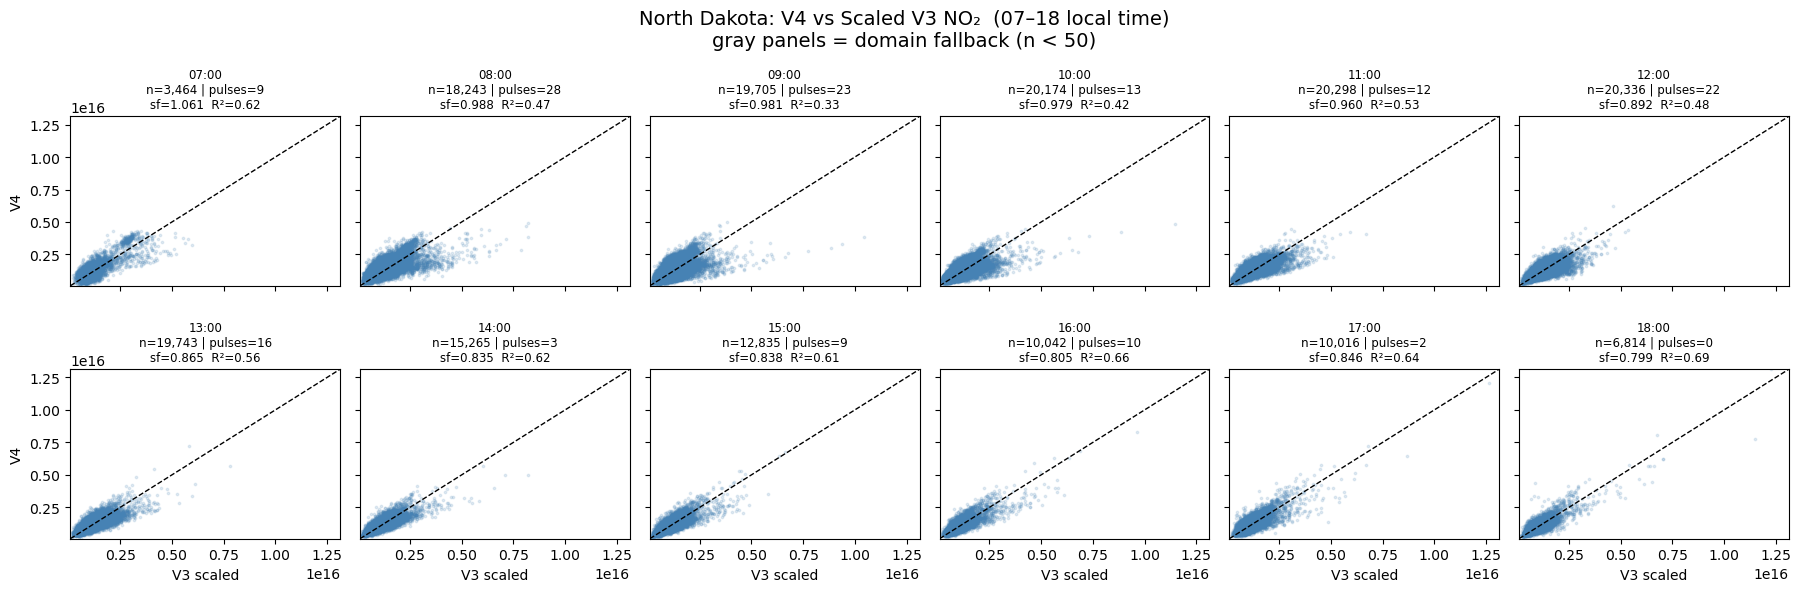

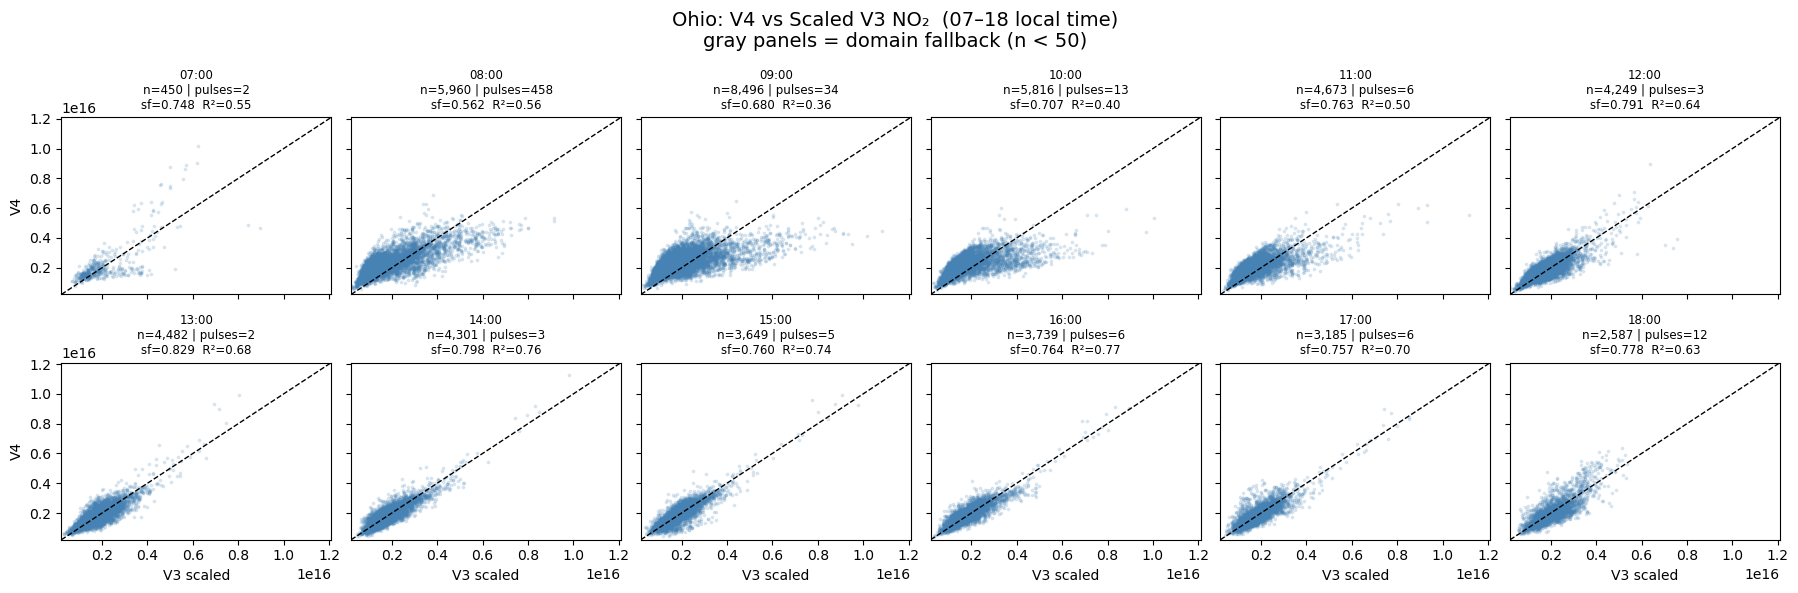

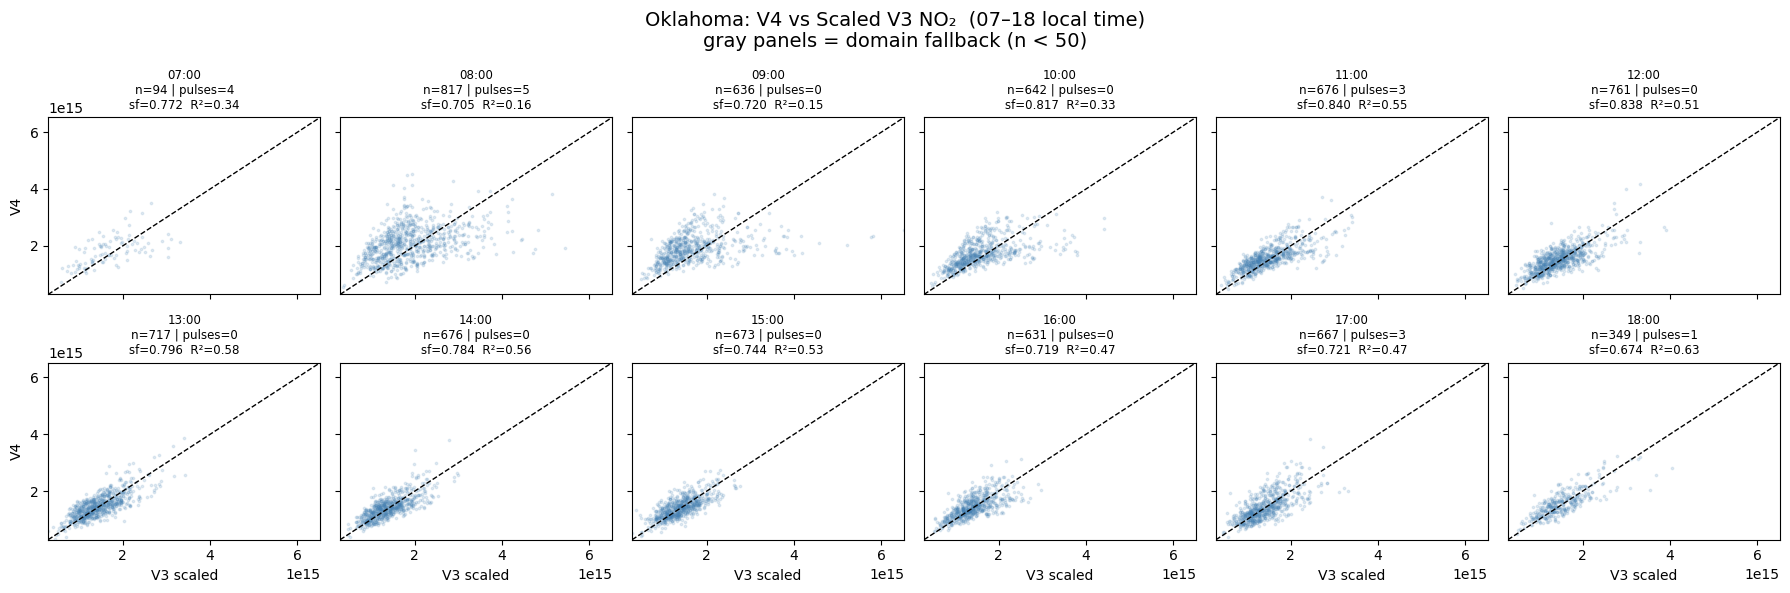

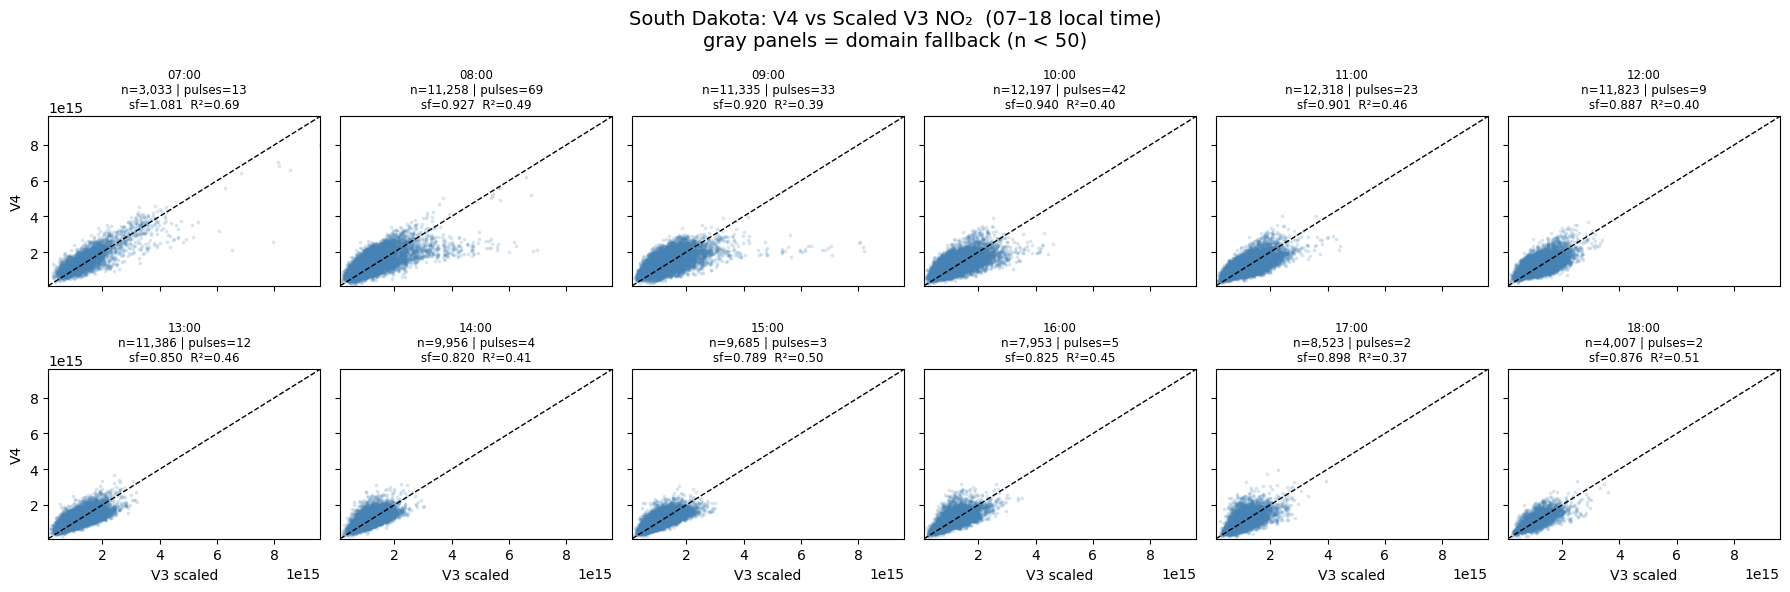

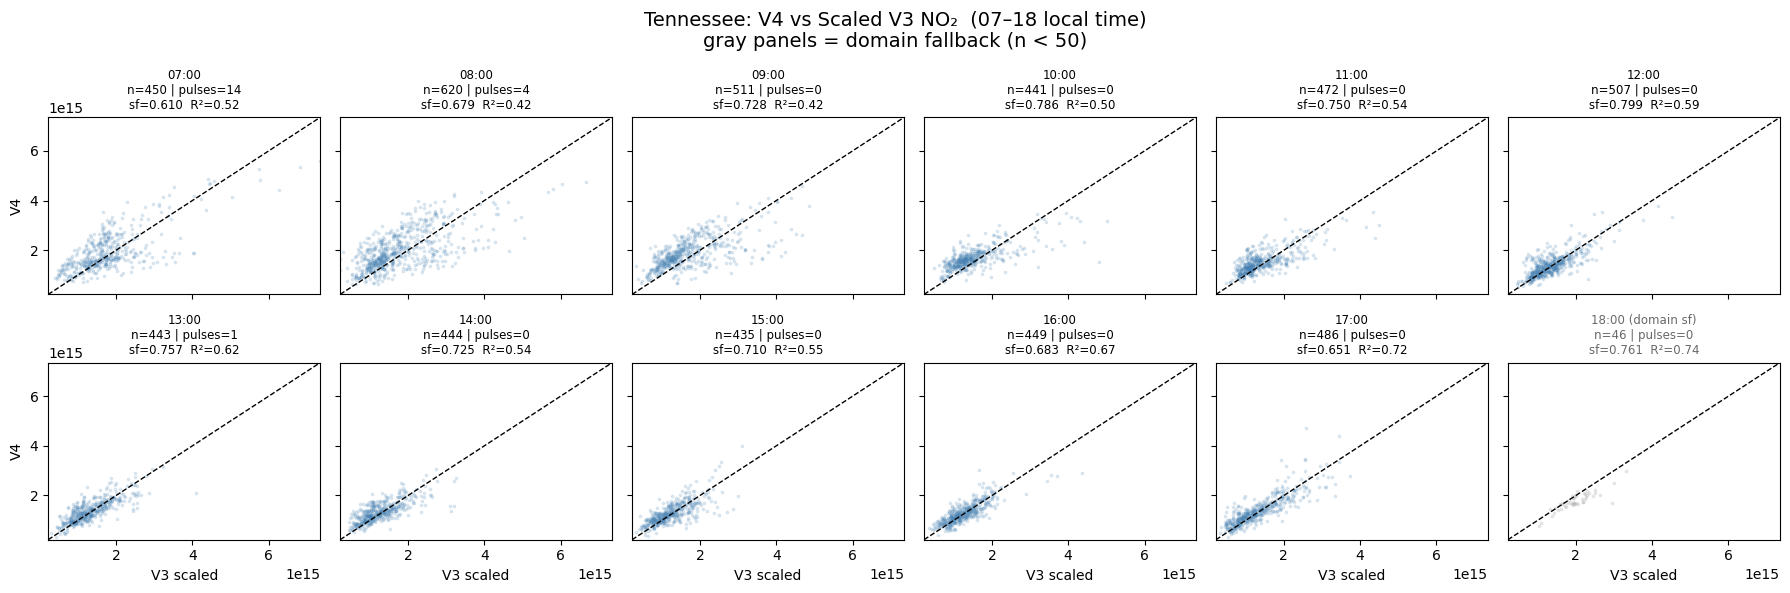

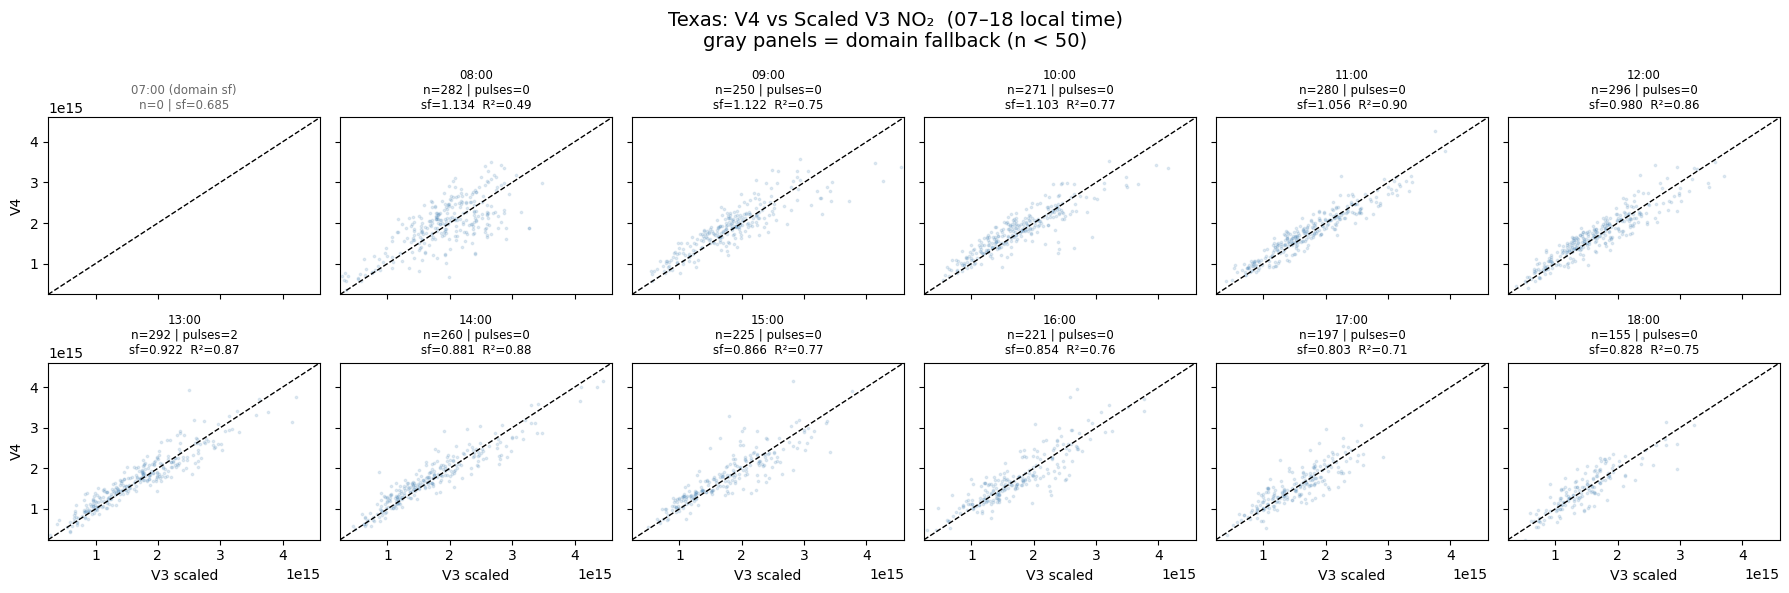

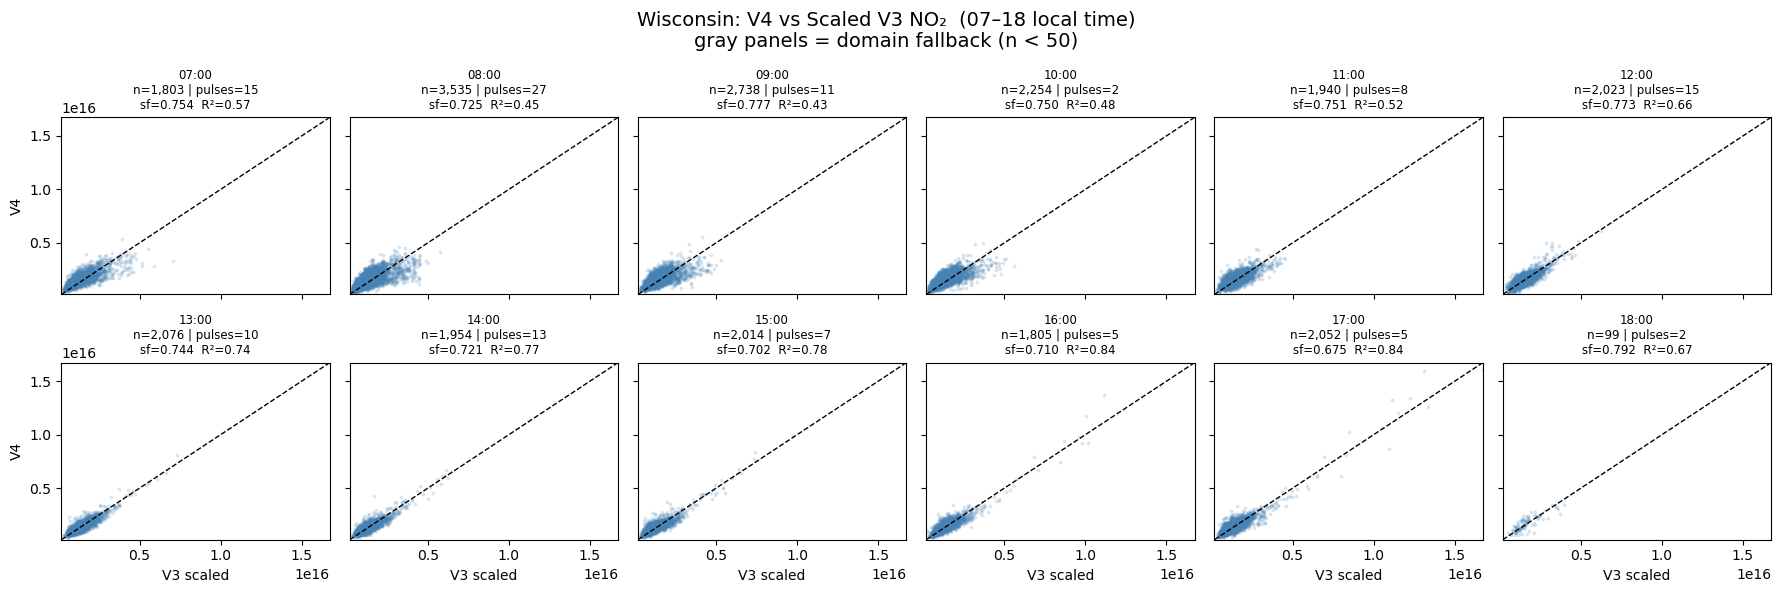

In [49]:
import numpy as np
import matplotlib.pyplot as plt

hours = list(range(7, 19))
states = sorted(merged["state_name"].dropna().unique())

for state in states:
    state_df = merged[merged["state_name"] == state].copy()

    if len(state_df) < 10:
        continue

    # apply state×hour scale factor to get scaled V3
    state_df["no2_v3_scaled"] = [
        row["no2_mean_v3"] * scale_map.get((row["state_name"], int(row["hour"])), np.nan)
        for _, row in state_df.iterrows()
    ]

    lims = [
        min(state_df["no2_v3_scaled"].min(), state_df["no2_mean_v4"].min()),
        max(state_df["no2_v3_scaled"].max(), state_df["no2_mean_v4"].max()),
    ]

    fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
    axes = axes.flatten()

    for i, h in enumerate(hours):
        ax = axes[i]
        subset = state_df[state_df["hour"] == h].dropna(
            subset=["no2_v3_scaled", "no2_mean_v4"]
        )
        pulses = subset[subset["pulse_start"] == True]

        # flag whether this cell used a fallback
        cell = state_hour_df[
            (state_hour_df["state"] == state) & (state_hour_df["hour"] == h)
        ]
        used_fallback = cell["used_fallback"].values[0] if len(cell) else True
        sf = cell[ESTIMATOR].values[0] if len(cell) else np.nan

        if len(subset) > 2:
            r = np.corrcoef(subset["no2_v3_scaled"], subset["no2_mean_v4"])[0, 1]
            r2 = r ** 2
        else:
            r2 = np.nan

        ax.scatter(
            subset["no2_v3_scaled"],
            subset["no2_mean_v4"],
            alpha=0.15,
            s=3,
            color="gray" if used_fallback else "steelblue",
        )
        # ax.scatter(
        #     pulses["no2_v3_scaled"],
        #     pulses["no2_mean_v4"],
        #     color="red",
        #     alpha=0.8,
        #     s=6,
        # )
        ax.plot(lims, lims, "k--", linewidth=1)

        fallback_label = " (domain sf)" if used_fallback else ""
        ax.set_title(
            f"{h:02d}:00{fallback_label}\n"
            f"n={len(subset):,} | pulses={len(pulses):,}\n"
            f"sf={sf:.3f}  R²={r2:.2f}" if not np.isnan(r2) else
            f"{h:02d}:00{fallback_label}\nn={len(subset):,} | sf={sf:.3f}",
            fontsize=8.5,
            color="dimgray" if used_fallback else "black",
        )
        ax.set_xlim(lims)
        ax.set_ylim(lims)

    for ax in axes[6:]:
        ax.set_xlabel("V3 scaled")
    for ax in axes[::6]:
        ax.set_ylabel("V4")

    fig.suptitle(
        f"{state}: V4 vs Scaled V3 NO₂  (07–18 local time)\n"
        f"gray panels = domain fallback (n < {MIN_N})",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()


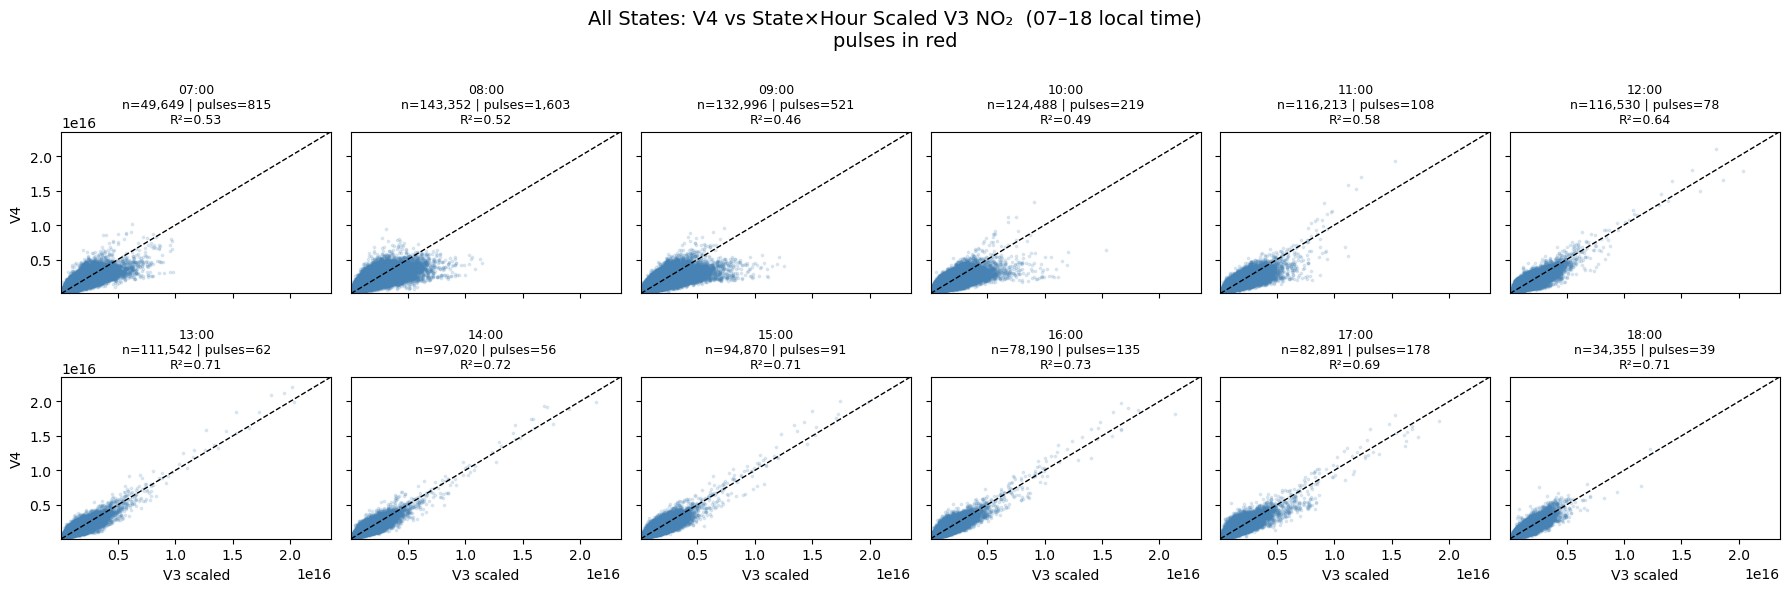

In [50]:
import numpy as np
import matplotlib.pyplot as plt

hours = list(range(7, 19))

# apply state x hour scale factor to full merged df
merged["no2_v3_scaled"] = [
    row["no2_mean_v3"] * scale_map.get((row["state_name"], int(row["hour"])), np.nan)
    for _, row in merged.iterrows()
]

lims = [
    min(merged["no2_v3_scaled"].min(), merged["no2_mean_v4"].min()),
    max(merged["no2_v3_scaled"].max(), merged["no2_mean_v4"].max()),
]

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged["hour"] == h].dropna(subset=["no2_v3_scaled", "no2_mean_v4"])
    pulses = subset[subset["pulse_start"] == True]

    if len(subset) > 2:
        r = np.corrcoef(subset["no2_v3_scaled"], subset["no2_mean_v4"])[0, 1]
        r2 = r ** 2
    else:
        r2 = np.nan

    ax.scatter(
        subset["no2_v3_scaled"],
        subset["no2_mean_v4"],
        alpha=0.15,
        s=3,
        color="steelblue",
    )
    # ax.scatter(
    #     pulses["no2_v3_scaled"],
    #     pulses["no2_mean_v4"],
    #     color="red",
    #     alpha=0.8,
    #     s=6,
    # )
    ax.plot(lims, lims, "k--", linewidth=1)

    ax.set_title(
        f"{h:02d}:00\nn={len(subset):,} | pulses={len(pulses):,}\nR²={r2:.2f}",
        fontsize=9,
    )
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes[6:]:
    ax.set_xlabel("V3 scaled")
for ax in axes[::6]:
    ax.set_ylabel("V4")

fig.suptitle(
    "All States: V4 vs State×Hour Scaled V3 NO₂  (07–18 local time)\npulses in red",
    fontsize=14,
)
plt.tight_layout()
plt.show()


In [56]:
domain_df

,hour,n,median_ratio,slope_origin,slope_ols,intercept_ols,r2_ols
0,7,50469,0.945731,0.684715,0.385902,8.948187e+14,0.514845
1,8,147694,0.945221,0.688939,0.386072,9.070079e+14,0.546811
2,9,138681,0.956101,0.743599,0.406915,9.060627e+14,0.495276
3,10,128456,0.955900,0.772543,0.438495,7.952899e+14,0.521301
4,11,119488,0.927226,0.807671,0.521464,6.201013e+14,0.598152
5,12,119409,0.896255,0.825452,0.595730,4.719288e+14,0.656963
6,13,114582,0.871340,0.818242,0.639110,3.648438e+14,0.716772
7,14,100361,0.837003,0.789891,0.634795,3.253914e+14,0.730695
8,15,98326,0.817739,0.765151,0.611909,3.287665e+14,0.722082
9,16,81647,0.796777,0.746262,0.605896,3.176257e+14,0.737889


In [57]:
state_hour_df

,state,hour,n,used_fallback,median_ratio,slope_origin,slope_ols,intercept_ols,r2_ols
0,Arkansas,7,346,False,0.736644,0.684119,0.423400,7.391881e+14,0.412984
1,Arkansas,8,671,False,0.881569,0.881800,0.675474,5.007504e+14,0.518411
2,Arkansas,9,483,False,0.980428,0.926473,0.546624,7.661260e+14,0.463282
3,Arkansas,10,410,False,0.986256,0.960403,0.608001,6.134270e+14,0.462032
4,Arkansas,11,365,False,0.964972,0.948373,0.577707,6.046595e+14,0.459948
...,...,...,...,...,...,...,...,...,...
211,Wisconsin,14,1954,False,0.757134,0.721096,0.591338,3.037347e+14,0.765523
212,Wisconsin,15,2014,False,0.735052,0.702046,0.579183,2.978703e+14,0.780757
213,Wisconsin,16,1805,False,0.732900,0.710410,0.639265,1.991827e+14,0.836607
214,Wisconsin,17,2052,False,0.718455,0.675232,0.603719,2.269100e+14,0.842924


In [58]:
# ── Export scaling factors ────────────────────────────────────────────────────
# Run this after the cells that build domain_df and state_hour_df.
#
# Outputs:
#   scaling_by_hour.csv           — one row per hour, domain-wide factors
#   scaling_by_state_and_hour.csv — one row per (state, hour), with fallback flag

# ── 1. Domain-wide (per hour) ─────────────────────────────────────────────────
hour_out = domain_df[["hour", "n", "slope_origin"]].copy()
hour_out = hour_out.sort_values("hour").reset_index(drop=True)

hour_out.to_parquet("/global/scratch/users/toireasamarie/Scaling Factors/scaling_by_hour.parquet", engine='pyarrow')
print("Saved: /global/scratch/users/toireasamarie/Scaling Factors/scaling_by_hour.parquet")
print(hour_out)

print()

# ── 2. State × hour ───────────────────────────────────────────────────────────
state_out = state_hour_df[["state", "hour", "n", "used_fallback","slope_origin"]].copy()
state_out = state_out.sort_values(["state", "hour"]).reset_index(drop=True)

state_out.to_parquet("/global/scratch/users/toireasamarie/Scaling Factors/scaling_by_state_and_hour.parquet", engine='pyarrow')
print("Saved: /global/scratch/users/toireasamarie/Scaling Factors/scaling_by_state_and_hour.parquet")
print(state_out)

Saved: /global/scratch/users/toireasamarie/Scaling Factors/scaling_by_hour.parquet
    hour       n  slope_origin
0      7   50469      0.684715
1      8  147694      0.688939
2      9  138681      0.743599
3     10  128456      0.772543
4     11  119488      0.807671
5     12  119409      0.825452
6     13  114582      0.818242
7     14  100361      0.789891
8     15   98326      0.765151
9     16   81647      0.746262
10    17   85713      0.744402
11    18   35947      0.761391

Saved: /global/scratch/users/toireasamarie/Scaling Factors/scaling_by_state_and_hour.parquet
         state  hour     n  used_fallback  slope_origin
0     Arkansas     7   346          False      0.684119
1     Arkansas     8   671          False      0.881800
2     Arkansas     9   483          False      0.926473
3     Arkansas    10   410          False      0.960403
4     Arkansas    11   365          False      0.948373
..         ...   ...   ...            ...           ...
211  Wisconsin    14  1954  